# Двухступенчатая свободная турбина на взлётном режиме

Расчёт для ЛМС-901 «Байкал». По заданной мощности после редуктора определяем расход газа и средний диаметр, рассчитываем две ступени, затем по состоянию газа за вторым колесом находим скорость и площадь выходного сопла.

[1. Исходные данные](#inputs) · [2. Цикл и расход](#cycle) · [3. Диаметр и число ступеней](#size) · [4. Обе ступени и мощность](#stages) · **[5. Выходное сопло](#nozzle)** · [6. Треугольники и профили](#span) · [Дополнительные варианты](#variants) · [Словарь переменных](#symbols)

**Сечения.** В каждой ступени 0 — вход в сопловой аппарат (СА), 1 — выход из СА и вход в рабочее колесо (РК), 2 — выход из РК. В выпускном устройстве 5 — сразу за РК второй ступени, 9 — срез сопла. Звёздочка означает полный параметр, индекс $s$ — изоэнтропическое состояние. Давления абсолютные.

**Как читать.** Над каждой вычисляемой величиной стоит её формула. Следующая ячейка Python вычисляет и выводит результат. В формулах и коде используются СИ, для вывода давление переводится в кПа, работа — в кДж/кг. После изменения исходных данных выполните **Run All**.

[Полное давление за СТ из цикла](#cycle-pressure) · [Сравнение со ступенями](#pressure-check)

[Степени расширения по ступеням](#stage-pressure-ratios)

В разделах 2–5 каждой величине соответствует отдельная числовая переменная. В расчёте ступеней суффикс `_1` означает I ступень, `_2` — II ступень. Например, `p2_1` и `p2t_1` — статическое и полное давления за первым рабочим колесом. В разделе 6 суффиксы `_sa1`, `_rk1`, `_sa2`, `_rk2` обозначают сечение за соответствующим венцом.

<a id="inputs"></a>
## 1. Исходные данные

В исходной точке $\pi_к^*=10$. Полная температура 1440 К задана в горле СА турбины высокого давления (ТВД) после возврата охлаждающего воздуха. ТВД приводит компрессор. Следующая за ней свободная турбина (СТ) передаёт мощность через редуктор.

Два коэффициента задают разные граничные условия. $r_p=p_н/p_5$ задаёт **статическое** противодавление ступени. $\sigma_с=p_9^*/p_5^*$ описывает потерю **полного** давления на участке от РК2 до среза.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


pd.set_option("display.precision", 5)

**Режим и газогенератор**

In [2]:
# Цикл и режим
N_req = 750_000  # Заданная мощность после редуктора, Вт
pi_design = 10.0  # Проектная степень повышения полного давления компрессора
n = 30_000  # Частота вращения свободной турбины, об/мин
Ta = 288.0  # Температура наружного воздуха, К
pa = 101_300.0  # Статическое давление атмосферы, Па
R = 287.4  # Удельная газовая постоянная модели, Дж/(кг·К)
sigma_in = 0.98  # Сохранение полного давления во входном устройстве
eta_poly = 0.83  # Политропический КПД компрессора
sigma_burn = 0.97  # Сохранение полного давления в камере сгорания
eta_burn = 0.995  # Коэффициент полноты сгорания
Qfuel = 43e6  # Низшая теплота сгорания топлива, Дж/кг
l0 = 14.61  # Стехиометрическая масса воздуха на 1 кг топлива, кг/кг
leak = 0.007  # Безвозвратные утечки в долях расхода воздуха компрессора
cool = 0.05  # Отбор на охлаждение в долях расхода воздуха компрессора
T4t = 1440.0  # Полная температура смеси в горле СА ТВД, К
eta_hpt = 0.90  # КПД ТВД по полным параметрам
eta_mech = 0.995  # Механический КПД в балансе каждого вала
eta_gear = 0.99  # КПД редуктора

**Предварительные параметры СТ и выпуска**

In [3]:
# Предварительная СТ и выпуск
eta_pre = 0.91  # Лопаточный КПД в предварительном цикле
c_pre = 210.0  # Заданная скорость за СТ в предварительном расчёте, м/с
rp = 0.995  # Отношение статических давлений атмосферы и газа за РК2
sigma_nozzle = 0.995  # Отношение полных давлений на срезе и за РК2
height_ratio = 1/5  # Отношение выходной высоты лопатки к среднему диаметру
y0 = 0.57  # Отношение скоростей для оценки числа ступеней
mu = 1.0  # Коэффициент использования выходной скорости
c_mean = 180.0  # Принятая средняя выходная скорость за ступенью для оценки числа ступеней, м/с

**Венцы и профили**

In [4]:
# Венцы и профили
reaction_I = 0.350  # Заданная реактивность I ступени на среднем радиусе
reaction_II = 0.415  # Заданная реактивность II ступени на среднем радиусе
angle1_I = 18.0  # Угол абсолютной скорости за СА1 от направления вращения, °
angle1_II = 24.5  # Угол абсолютной скорости за СА2 от направления вращения, °
angle2_I = 90.0  # Угол абсолютной скорости за РК1 от направления против вращения, °
phi_I = 0.96  # Коэффициент скорости соплового аппарата I ступени
phi_II = 0.96  # Коэффициент скорости соплового аппарата II ступени
psi_I = 0.9704670965605235  # Коэффициент скорости РК I ступени, подбор в исходной точке
psi_II = 0.9704670965605235  # Коэффициент скорости РК II ступени, подбор в исходной точке
gap = 0.0003  # Радиальный зазор обоих РК, м
thickness = 0.10  # Относительная максимальная толщина профиля
pitch_ratio = 0.82  # Заданный относительный шаг на среднем радиусе

**Дополнительные варианты и механическая оценка**

In [5]:
# Параметры дополнительных вариантов
c_target = 200.0  # Заданная скорость для обратного расчёта сопла, м/с
stress_limit = 320.0  # Принятое предельное напряжение в эмпирической оценке, МПа
kn = 6.8e-6  # Коэффициент эмпирической формулы напряжения, МПа/[м²·(об/мин)²]
takeoff_min = 5.0  # Продолжительность взлётного режима для оценки массы топлива, мин
Kscheme = 0.8  # Поправка на схему двигателя в формуле массы
Kresource = 1.0  # Поправка на ресурс двигателя в формуле массы

<a id="cycle"></a>
## 2. Цикл и расход газа

Расходы топлива и воздуха отнесены к 1 кг воздуха на входе в компрессор. Проектная точка выбирается параметром `pi_design`. Здесь считаем только проектный режим. Остальные степени повышения давления сравниваются в приложении А.

**Истинная теплоёмкость воздуха и продуктов сгорания**

Коэффициенты и обе температурные ветви приведены в [приложении Б](#properties). Для воздуха используется предел α → ∞.

$$
c_p=c_p(T,\alpha)
$$

In [6]:
def cp_true(T, alpha=math.inf):
    """Истинная теплоёмкость при T, Дж/(кг·К). По умолчанию — воздух."""
    if alpha <= 0.2:
        raise ValueError("Для полинома нужна величина α > 0,2.")
    if T < 750:
        A = 0.0025 * T - 0.875
        B = 0.000025 * T**2 - 0.0275 * T + 6.5625
        value = 0.2407 + 0.0174/alpha
        value += (0.0193 + 0.0093/alpha) * A
        value += (0.002 - 0.001056/(alpha-0.2)) * B
    else:
        C = 0.001176 * T - 0.88235
        E = 0.0000055556 * T**2 - 0.013056 * T + 6.67
        value = 0.26 + 0.0267/alpha
        value += (0.032 + 0.0133/alpha) * C
        value -= (0.00374 + 0.0094/(alpha**2+10)) * E
    return 4187 * value



print(f"При Tн: {cp_true(Ta):.3f} Дж/(кг·К)")

При Tн: 1001.282 Дж/(кг·К)


**Средняя теплоёмкость для энтальпии смеси**

$$
h(T,\alpha)-h(288,\alpha)=c_{pm}(T,\alpha)T-c_{pm}(288,\alpha)\,288
$$

In [7]:
def cp_mean(T, alpha=math.inf):
    """Средняя теплоёмкость для вычисления энтальпии, Дж/(кг·К)."""
    if T < 700:
        value = 0.236 + (1.2 + 2.25/alpha) * 1e-5 * (T-70)
    else:
        value = 0.218 + (2.2 + 1.25/alpha) * 1e-5 * (T+450)
    return 4187 * value

print(f"При 288 К: {cp_mean(288):.3f} Дж/(кг·К)")

При 288 К: 999.085 Дж/(кг·К)


### 2.1. Компрессор

Начинаем с $k=1{,}4$. По температуре газа уточняем теплоёмкость и показатель адиабаты. Сохраняем три прохода исходного расчёта.

In [8]:
if pi_design <= 1:
    raise ValueError("Степень повышения давления должна превышать единицу.")
k_comp_start = 1.4
print("Проектная степень сжатия:", pi_design)

Проектная степень сжатия: 10.0


**Давление перед компрессором**

$$
p_{\rm вх}^*=\sigma_{\rm вх}p_{\rm н}
$$

In [9]:
p_in = sigma_in * pa
print(f"Давление перед компрессором = {p_in / 1000:.3f} кПа")

Давление перед компрессором = 99.274 кПа


**Давление за компрессором**

$$
p_{\rm к}^*=\pi_{\rm к}^*p_{\rm вх}^*
$$

In [10]:
p_comp_out = pi_design * p_in
print(f"Давление за компрессором = {p_comp_out / 1000:.3f} кПа")

Давление за компрессором = 992.740 кПа


#### Компрессор · проход 1

**Показатель степени**

$$
e=(k-1)/k
$$

In [11]:
exponent_comp_iter1 = (k_comp_start - 1) / k_comp_start
print(f"Показатель степени = {exponent_comp_iter1:.6f}")

Показатель степени = 0.285714


**Адиабатический КПД компрессора**

$$
\eta_{\rm к}=\frac{(\pi_{\rm к}^*)^e-1}{(\pi_{\rm к}^*)^{e/\eta_{\rm пол}}-1}
$$

In [12]:
eta_comp_iter1 = (pi_design**exponent_comp_iter1 - 1) / (pi_design**(exponent_comp_iter1 / eta_poly) - 1)
print(f"Адиабатический КПД компрессора = {eta_comp_iter1:.6f}")

Адиабатический КПД компрессора = 0.769684


**Полная температура после компрессора**

$$
T_{\rm к}^*=T_{\rm н}[1+((\pi_{\rm к}^*)^e-1)/\eta_{\rm к}]
$$

In [13]:
T_comp_out_iter1 = Ta * (1 + (pi_design**exponent_comp_iter1 - 1) / eta_comp_iter1)
print(f"Полная температура после компрессора = {T_comp_out_iter1:.3f} К")

Полная температура после компрессора = 636.248 К


**Теплоёмкость воздуха при средней температуре**

$$
c_{p\rm в}=c_p\!\left((T_{\rm н}+T_{\rm к}^*)/2\right)
$$

In [14]:
cp_air_iter1 = cp_true((Ta + T_comp_out_iter1) / 2)
print(f"Теплоёмкость воздуха при средней температуре = {cp_air_iter1:.3f} Дж/(кг·К)")

Теплоёмкость воздуха при средней температуре = 1023.705 Дж/(кг·К)


**Показатель адиабаты следующего прохода**

$$
k=c_{p\rm в}/(c_{p\rm в}-R)
$$

In [15]:
k_comp_iter1 = cp_air_iter1 / (cp_air_iter1 - R)
print(f"Показатель адиабаты следующего прохода = {k_comp_iter1:.6f}")

Показатель адиабаты следующего прохода = 1.390327


#### Компрессор · проход 2

**Показатель степени**

$$
e=(k-1)/k
$$

In [16]:
exponent_comp_iter2 = (k_comp_iter1 - 1) / k_comp_iter1
print(f"Показатель степени = {exponent_comp_iter2:.6f}")

Показатель степени = 0.280745


**Адиабатический КПД компрессора**

$$
\eta_{\rm к}=\frac{(\pi_{\rm к}^*)^e-1}{(\pi_{\rm к}^*)^{e/\eta_{\rm пол}}-1}
$$

In [17]:
eta_comp_iter2 = (pi_design**exponent_comp_iter2 - 1) / (pi_design**(exponent_comp_iter2 / eta_poly) - 1)
print(f"Адиабатический КПД компрессора = {eta_comp_iter2:.6f}")

Адиабатический КПД компрессора = 0.770799


**Полная температура после компрессора**

$$
T_{\rm к}^*=T_{\rm н}[1+((\pi_{\rm к}^*)^e-1)/\eta_{\rm к}]
$$

In [18]:
T_comp_out_iter2 = Ta * (1 + (pi_design**exponent_comp_iter2 - 1) / eta_comp_iter2)
print(f"Полная температура после компрессора = {T_comp_out_iter2:.3f} К")

Полная температура после компрессора = 627.537 К


**Теплоёмкость воздуха при средней температуре**

$$
c_{p\rm в}=c_p\!\left((T_{\rm н}+T_{\rm к}^*)/2\right)
$$

In [19]:
cp_air_iter2 = cp_true((Ta + T_comp_out_iter2) / 2)
print(f"Теплоёмкость воздуха при средней температуре = {cp_air_iter2:.3f} Дж/(кг·К)")

Теплоёмкость воздуха при средней температуре = 1022.989 Дж/(кг·К)


**Показатель адиабаты следующего прохода**

$$
k=c_{p\rm в}/(c_{p\rm в}-R)
$$

In [20]:
k_comp_iter2 = cp_air_iter2 / (cp_air_iter2 - R)
print(f"Показатель адиабаты следующего прохода = {k_comp_iter2:.6f}")

Показатель адиабаты следующего прохода = 1.390707


#### Компрессор · проход 3

**Показатель степени**

$$
e=(k-1)/k
$$

In [21]:
exponent_comp = (k_comp_iter2 - 1) / k_comp_iter2
print(f"Показатель степени = {exponent_comp:.6f}")

Показатель степени = 0.280941


**Адиабатический КПД компрессора**

$$
\eta_{\rm к}=\frac{(\pi_{\rm к}^*)^e-1}{(\pi_{\rm к}^*)^{e/\eta_{\rm пол}}-1}
$$

In [22]:
eta_comp = (pi_design**exponent_comp - 1) / (pi_design**(exponent_comp / eta_poly) - 1)
print(f"Адиабатический КПД компрессора = {eta_comp:.6f}")

Адиабатический КПД компрессора = 0.770755


**Полная температура после компрессора**

$$
T_{\rm к}^*=T_{\rm н}[1+((\pi_{\rm к}^*)^e-1)/\eta_{\rm к}]
$$

In [23]:
T_comp_out = Ta * (1 + (pi_design**exponent_comp - 1) / eta_comp)
print(f"Полная температура после компрессора = {T_comp_out:.3f} К")

Полная температура после компрессора = 627.879 К


**Теплоёмкость воздуха при средней температуре**

$$
c_{p\rm в}=c_p\!\left((T_{\rm н}+T_{\rm к}^*)/2\right)
$$

In [24]:
cp_air = cp_true((Ta + T_comp_out) / 2)
print(f"Теплоёмкость воздуха при средней температуре = {cp_air:.3f} Дж/(кг·К)")

Теплоёмкость воздуха при средней температуре = 1023.017 Дж/(кг·К)


**Удельная работа компрессора**

$$
L_{\rm к}=c_{p\rm в}(T_{\rm к}^*-T_{\rm н})
$$

In [25]:
L_comp = cp_air * (T_comp_out - Ta)
print(f"Удельная работа компрессора = {L_comp / 1000:.3f} кДж/кг воздуха")

Удельная работа компрессора = 347.702 кДж/кг воздуха


### 2.2. Камера сгорания и возврат воздуха охлаждения

Энтальпии в балансе отсчитываются от 288 К. Охлаждающий воздух возвращается к горлу СА ТВД, где задана полная температура смеси 1440 К в проектном варианте.

**Доля воздуха, поступающая в камеру сгорания**

$$
g_{\rm в,КС}=1-g_{\rm ут}-g_{\rm охл}
$$

In [26]:
burn_air = 1 - leak - cool
print(f"Доля воздуха, поступающая в камеру сгорания = {burn_air:.4f} кг/кг воздуха")

Доля воздуха, поступающая в камеру сгорания = 0.9430 кг/кг воздуха


**Доля воздуха в смеси после возврата охлаждения**

$$
g_{\rm в,см}=1-g_{\rm ут}
$$

In [27]:
mix_air = 1 - leak
print(f"Доля воздуха в смеси после возврата охлаждения = {mix_air:.4f} кг/кг воздуха")

Доля воздуха в смеси после возврата охлаждения = 0.9930 кг/кг воздуха


**Энтальпия воздуха после компрессора**

$$
h_{\rm в}=c_{pm}(T_{\rm к}^*)T_{\rm к}^*-c_{pm}(288)\,288
$$

In [28]:
h_air = cp_mean(T_comp_out) * T_comp_out - cp_mean(288) * 288
print(f"Энтальпия воздуха после компрессора = {h_air / 1000:.3f} кДж/кг")

Энтальпия воздуха после компрессора = 350.290 кДж/кг


**Начальное приближение избытка воздуха**

$$
\alpha^{(0)}=1/(0{,}025l_0)
$$

In [29]:
alpha_iter1 = 1 / (0.025 * l0)
print(f"Начальное приближение избытка воздуха = {alpha_iter1:.6f}")

Начальное приближение избытка воздуха = 2.737851


#### Топливный баланс · проход 1

**Энтальпия газа после смешения**

$$
h_{\rm г}=c_{pm}(T_4^*,\alpha)T_4^*-c_{pm}(288,\alpha)\,288
$$

In [30]:
h_gas_iter1 = cp_mean(T4t, alpha_iter1) * T4t - cp_mean(288, alpha_iter1) * 288
print(f"Энтальпия газа после смешения = {h_gas_iter1 / 1000:.3f} кДж/кг")

Энтальпия газа после смешения = 1327.210 кДж/кг


**Относительный расход топлива**

$$
f=\frac{(1-g_{\rm ут})(h_{\rm г}-h_{\rm в})}{\eta_{\rm г}Q_{\rm н}-h_{\rm г}}
$$

In [31]:
fuel_ratio_iter1 = mix_air * (h_gas_iter1 - h_air) / (eta_burn * Qfuel - h_gas_iter1)
print(f"Относительный расход топлива = {fuel_ratio_iter1:.8f} кг/кг воздуха")

Относительный расход топлива = 0.02339926 кг/кг воздуха


**Избыток воздуха после смешения**

$$
\alpha_{\rm см}=(1-g_{\rm ут})/(fl_0)
$$

In [32]:
alpha_iter2 = mix_air / (fuel_ratio_iter1 * l0)
print(f"Избыток воздуха после смешения = {alpha_iter2:.6f}")

Избыток воздуха после смешения = 2.904671


#### Топливный баланс · проход 2

**Энтальпия газа после смешения**

$$
h_{\rm г}=c_{pm}(T_4^*,\alpha)T_4^*-c_{pm}(288,\alpha)\,288
$$

In [33]:
h_gas = cp_mean(T4t, alpha_iter2) * T4t - cp_mean(288, alpha_iter2) * 288
print(f"Энтальпия газа после смешения = {h_gas / 1000:.3f} кДж/кг")

Энтальпия газа после смешения = 1324.347 кДж/кг


**Относительный расход топлива**

$$
f=\frac{(1-g_{\rm ут})(h_{\rm г}-h_{\rm в})}{\eta_{\rm г}Q_{\rm н}-h_{\rm г}}
$$

In [34]:
fuel_ratio = mix_air * (h_gas - h_air) / (eta_burn * Qfuel - h_gas)
print(f"Относительный расход топлива = {fuel_ratio:.8f} кг/кг воздуха")

Относительный расход топлива = 0.02332905 кг/кг воздуха


**Избыток воздуха после смешения**

$$
\alpha_{\rm см}=(1-g_{\rm ут})/(fl_0)
$$

In [35]:
alpha = mix_air / (fuel_ratio * l0)
print(f"Избыток воздуха после смешения = {alpha:.6f}")

Избыток воздуха после смешения = 2.913412


**Коэффициент избытка воздуха в КС**

$$
\alpha_{\rm КС}=g_{\rm в,КС}/(fl_0)
$$

In [36]:
alpha_burn = burn_air / (fuel_ratio * l0)
print(f"Коэффициент избытка воздуха в КС = {alpha_burn:.6f}")

Коэффициент избытка воздуха в КС = 2.766715


**Масса газа на единицу массы воздуха**

$$
m_{\rm г}=1-g_{\rm ут}+f
$$

In [37]:
gas_mass_ratio = mix_air + fuel_ratio
print(f"Масса газа на единицу массы воздуха = {gas_mass_ratio:.6f} кг/кг воздуха")

Масса газа на единицу массы воздуха = 1.016329 кг/кг воздуха


### 2.3. Турбина высокого давления

ТВД обеспечивает мощность компрессора. В её работе учитываются относительная масса газа и механический КПД общего вала.

**Удельная работа ТВД**

$$
L_{\rm ТВД}=L_{\rm к}/(m_{\rm г}\eta_{\rm м})
$$

In [38]:
L_hpt = L_comp / (gas_mass_ratio * eta_mech)
print(f"Удельная работа ТВД = {L_hpt / 1000:.3f} кДж/кг газа")

Удельная работа ТВД = 343.835 кДж/кг газа


**Полное давление в горле СА ТВД**

$$
p_4^*=\sigma_{\rm КС}p_{\rm к}^*
$$

In [39]:
p4t = sigma_burn * p_comp_out
print(f"Полное давление в горле СА ТВД = {p4t / 1000:.3f} кПа")

Полное давление в горле СА ТВД = 962.958 кПа


#### Температура за ТВД · проход 1

**Теплоёмкость газа в ТВД**

$$
c_{p\rm ТВД}=c_p\!\left(T_4^*,\alpha_{\rm см}\right)
$$

In [40]:
cp_hpt_iter1 = cp_true(T4t, alpha)
print(f"Теплоёмкость газа в ТВД = {cp_hpt_iter1:.3f} Дж/(кг·К)")

Теплоёмкость газа в ТВД = 1262.029 Дж/(кг·К)


**Полная температура перед свободной турбиной**

$$
T_{\rm СТ,вх}^*=T_4^*-L_{\rm ТВД}/c_{p\rm ТВД}
$$

In [41]:
Tin_iter1 = T4t - L_hpt / cp_hpt_iter1
print(f"Полная температура перед свободной турбиной = {Tin_iter1:.3f} К")

Полная температура перед свободной турбиной = 1167.554 К


#### Температура за ТВД · проход 2

**Теплоёмкость газа в ТВД**

$$
c_{p\rm ТВД}=c_p\!\left((T_4^*+T_{\mathrm{СТ,вх}}^{*,\mathrm{пред.}})/2,\alpha_{\rm см}\right)
$$

In [42]:
cp_hpt_iter2 = cp_true((T4t + Tin_iter1) / 2, alpha)
print(f"Теплоёмкость газа в ТВД = {cp_hpt_iter2:.3f} Дж/(кг·К)")

Теплоёмкость газа в ТВД = 1242.803 Дж/(кг·К)


**Полная температура перед свободной турбиной**

$$
T_{\rm СТ,вх}^*=T_4^*-L_{\rm ТВД}/c_{p\rm ТВД}
$$

In [43]:
Tin_iter2 = T4t - L_hpt / cp_hpt_iter2
print(f"Полная температура перед свободной турбиной = {Tin_iter2:.3f} К")

Полная температура перед свободной турбиной = 1163.339 К


#### Температура за ТВД · проход 3

**Теплоёмкость газа в ТВД**

$$
c_{p\rm ТВД}=c_p\!\left((T_4^*+T_{\mathrm{СТ,вх}}^{*,\mathrm{пред.}})/2,\alpha_{\rm см}\right)
$$

In [44]:
cp_hpt = cp_true((T4t + Tin_iter2) / 2, alpha)
print(f"Теплоёмкость газа в ТВД = {cp_hpt:.3f} Дж/(кг·К)")

Теплоёмкость газа в ТВД = 1242.477 Дж/(кг·К)


**Полная температура перед свободной турбиной**

$$
T_{\rm СТ,вх}^*=T_4^*-L_{\rm ТВД}/c_{p\rm ТВД}
$$

In [45]:
Tin = T4t - L_hpt / cp_hpt
print(f"Полная температура перед свободной турбиной = {Tin:.3f} К")

Полная температура перед свободной турбиной = 1163.266 К


**Температурное отношение для изоэнтропического расширения ТВД**

$$
\theta_s=1-L_{\rm ТВД}/(\eta_{\rm ТВД}^*c_{p\rm ТВД}T_4^*)
$$

In [46]:
theta_hpt = 1 - L_hpt / (eta_hpt * cp_hpt * T4t)
print(f"Температурное отношение для изоэнтропического расширения ТВД = {theta_hpt:.6f}")

Температурное отношение для изоэнтропического расширения ТВД = 0.786471


**Полное давление перед свободной турбиной**

$$
p_{\rm СТ,вх}^*=p_4^*\theta_s^{c_{p\rm ТВД}/R}
$$

In [47]:
if theta_hpt <= 0:
    raise ValueError("Проверьте перепад в ТВД.")
pin = p4t * theta_hpt**(cp_hpt / R)
print(f"Полное давление перед СТ = {pin/1000:.3f} кПа")

Полное давление перед СТ = 340.900 кПа


### 2.4. Предварительный расчёт свободной турбины

Расширение задано от полного давления перед СТ до статического давления за последним колесом. На выходе задан модуль абсолютной скорости $c_{пред}$.

**Статическое давление за СТ**

$$
p_5=p_{\rm н}/r_p
$$

In [48]:
p5 = pa / rp
if pin <= p5:
    raise ValueError("Для расширения в СТ требуется p*вх > p₅.")
print(f"Статическое давление за СТ = {p5 / 1000:.3f} кПа")

Статическое давление за СТ = 101.809 кПа


#### Теплоперепад свободной турбины · проход 1

**Начальная теплоёмкость газа для СТ**

$$
c_{p\rm СТ}^{(1)}=c_{p\rm ТВД}
$$

In [49]:
cp_pt_iter1 = cp_hpt
print(f"Начальная теплоёмкость газа для СТ = {cp_pt_iter1:.3f} Дж/(кг·К)")

Начальная теплоёмкость газа для СТ = 1242.477 Дж/(кг·К)


**Располагаемый теплоперепад СТ**

$$
H_{\rm СТ}=c_{p\rm СТ}T_{\rm СТ,вх}^*\left[1-(p_5/p_{\rm СТ,вх}^*)^{R/c_{p\rm СТ}}\right]
$$

In [50]:
Hpt_iter1 = cp_pt_iter1 * Tin * (1 - (p5 / pin)**(R / cp_pt_iter1))
print(f"Располагаемый теплоперепад СТ = {Hpt_iter1 / 1000:.3f} кДж/кг")

Располагаемый теплоперепад СТ = 352.469 кДж/кг


**Статическая температура за СТ по циклу**

$$
T_{5,\rm цикл}=T_{\rm СТ,вх}^*-\eta_{\rm лоп,пред}H_{\rm СТ}/c_{p\rm СТ}
$$

In [51]:
Tpre_iter1 = Tin - eta_pre * Hpt_iter1 / cp_pt_iter1
print(f"Статическая температура за СТ по циклу = {Tpre_iter1:.3f} К")

Статическая температура за СТ по циклу = 905.115 К


#### Теплоперепад свободной турбины · проход 2

**Уточнённая теплоёмкость газа для СТ**

$$
c_{p\rm СТ}=c_p((T_{\rm СТ,вх}^*+T_{5,\rm пред})/2,\alpha_{\rm см})
$$

In [52]:
cp_pt_iter2 = cp_true((Tin + Tpre_iter1) / 2, alpha)
print(f"Уточнённая теплоёмкость газа для СТ = {cp_pt_iter2:.3f} Дж/(кг·К)")

Уточнённая теплоёмкость газа для СТ = 1193.944 Дж/(кг·К)


**Располагаемый теплоперепад СТ**

$$
H_{\rm СТ}=c_{p\rm СТ}T_{\rm СТ,вх}^*\left[1-(p_5/p_{\rm СТ,вх}^*)^{R/c_{p\rm СТ}}\right]
$$

In [53]:
Hpt_iter2 = cp_pt_iter2 * Tin * (1 - (p5 / pin)**(R / cp_pt_iter2))
print(f"Располагаемый теплоперепад СТ = {Hpt_iter2 / 1000:.3f} кДж/кг")

Располагаемый теплоперепад СТ = 350.567 кДж/кг


**Статическая температура за СТ по циклу**

$$
T_{5,\rm цикл}=T_{\rm СТ,вх}^*-\eta_{\rm лоп,пред}H_{\rm СТ}/c_{p\rm СТ}
$$

In [54]:
Tpre_iter2 = Tin - eta_pre * Hpt_iter2 / cp_pt_iter2
print(f"Статическая температура за СТ по циклу = {Tpre_iter2:.3f} К")

Статическая температура за СТ по циклу = 896.071 К


#### Теплоперепад свободной турбины · проход 3

**Уточнённая теплоёмкость газа для СТ**

$$
c_{p\rm СТ}=c_p((T_{\rm СТ,вх}^*+T_{5,\rm пред})/2,\alpha_{\rm см})
$$

In [55]:
cp_pt = cp_true((Tin + Tpre_iter2) / 2, alpha)
print(f"Уточнённая теплоёмкость газа для СТ = {cp_pt:.3f} Дж/(кг·К)")

Уточнённая теплоёмкость газа для СТ = 1193.001 Дж/(кг·К)


**Располагаемый теплоперепад СТ**

$$
H_{\rm СТ}=c_{p\rm СТ}T_{\rm СТ,вх}^*\left[1-(p_5/p_{\rm СТ,вх}^*)^{R/c_{p\rm СТ}}\right]
$$

In [56]:
Hpt = cp_pt * Tin * (1 - (p5 / pin)**(R / cp_pt))
print(f"Располагаемый теплоперепад СТ = {Hpt / 1000:.3f} кДж/кг")

Располагаемый теплоперепад СТ = 350.528 кДж/кг


**Статическая температура за СТ по циклу**

$$
T_{5,\rm цикл}=T_{\rm СТ,вх}^*-\eta_{\rm лоп,пред}H_{\rm СТ}/c_{p\rm СТ}
$$

In [57]:
Tpre = Tin - eta_pre * Hpt / cp_pt
print(f"Статическая температура за СТ по циклу = {Tpre:.3f} К")

Статическая температура за СТ по циклу = 895.890 К


**Удельная работа свободной турбины по циклу**

$$
L_{\rm СТ,цикл}=\eta_{\rm лоп,пред}H_{\rm СТ}-c_{\rm пред}^2/2
$$

In [58]:
Lpt = eta_pre * Hpt - c_pre**2 / 2
print(f"Удельная работа свободной турбины по циклу = {Lpt / 1000:.3f} кДж/кг")

Удельная работа свободной турбины по циклу = 296.931 кДж/кг


<a id="cycle-pressure"></a>
### 2.5. Полное давление за СТ отдельно по циклу

Сечение 5 расположено сразу за РК II, до выпускного сопла. На данном шаге используются только параметры предварительного цикла. При принятой постоянной теплоёмкости полное состояние восстанавливается изоэнтропическим торможением газа в этом сечении.

**Полная температура за СТ по циклу**

$$
T_{5,\rm цикл}^*=T_{5,\rm цикл}+\frac{c_{\rm пред}^2}{2c_{p\rm СТ}}
$$

In [59]:
T5t_cycle = Tpre + c_pre**2 / (2 * cp_pt)
print(f"Полная температура за СТ по циклу = {T5t_cycle:.4f} К")

Полная температура за СТ по циклу = 914.3725 К


**Полное давление за СТ по циклу**

$$
p_{5,\rm цикл}^*=p_5\left(\frac{T_{5,\rm цикл}^*}{T_{5,\rm цикл}}\right)^{c_{p\rm СТ}/R}
$$

In [60]:
p5t_cycle = p5 * (T5t_cycle / Tpre)**(cp_pt / R)
print(f"Полное давление за СТ по циклу = {p5t_cycle / 1000:.6f} кПа")

Полное давление за СТ по циклу = 110.815393 кПа


### 2.6. Массовые расходы проектного режима

Предварительный расход следует из мощности после редуктора. Для выбора геометрии его округляем вверх до 0,001 кг/с.

**Предварительный расход газа**

$$
G_{\rm г,пред}=N_{\rm зад}/(L_{\rm СТ,цикл}\eta_{\rm м}\eta_{\rm р})
$$

In [61]:
if Lpt <= 0:
    raise ValueError("Неположительная работа свободной турбины.")
G_pre = N_req / (Lpt * eta_mech * eta_gear)
print(f"Предварительный расход газа = {G_pre:.6f} кг/с")

Предварительный расход газа = 2.564174 кг/с


**Расход газа для расчёта венцов**

$$
G_{\rm г}=\lceil 1000 G_{\rm г,пред}\rceil/1000
$$

In [62]:
G = math.ceil(1000 * G_pre) / 1000
print(f"Расход газа для расчёта венцов = {G:.6f} кг/с")

Расход газа для расчёта венцов = 2.565000 кг/с


**Расход воздуха компрессора**

$$
G_{\rm в}=G_{\rm г}/m_{\rm г}
$$

In [63]:
Gair = G / gas_mass_ratio
print(f"Расход воздуха компрессора = {Gair:.6f} кг/с")

Расход воздуха компрессора = 2.523789 кг/с


**Расход воздуха в КС**

$$
G_{\rm в,КС}=g_{\rm в,КС}G_{\rm в}
$$

In [64]:
Gair_burn = burn_air * Gair
print(f"Расход воздуха в КС = {Gair_burn:.6f} кг/с")

Расход воздуха в КС = 2.379933 кг/с


**Расход охлаждающего воздуха**

$$
G_{\rm охл}=g_{\rm охл}G_{\rm в}
$$

In [65]:
Gcool = cool * Gair
print(f"Расход охлаждающего воздуха = {Gcool:.6f} кг/с")

Расход охлаждающего воздуха = 0.126189 кг/с


**Утечка воздуха**

$$
G_{\rm ут}=g_{\rm ут}G_{\rm в}
$$

In [66]:
Gleak = leak * Gair
print(f"Утечка воздуха = {Gleak:.6f} кг/с")

Утечка воздуха = 0.017667 кг/с


**Расход топлива**

$$
G_{\rm т}=fG_{\rm в}
$$

In [67]:
Gfuel = fuel_ratio * Gair
print(f"Расход топлива = {Gfuel:.6f} кг/с")

Расход топлива = 0.058878 кг/с


<a id="size"></a>
## 3. Средний диаметр и число ступеней

При постоянном среднем диаметре кольцевая площадь равна $\pi D_m l$. Для предварительной оценки площади принята осевая выходная скорость $c_{пред}$.

**Выходная площадь для выбора диаметра**

$$
A_{\rm пред}=G_{\rm г}RT_{5,\rm цикл}/(p_5c_{\rm пред})
$$

In [68]:
A_pre = G * R * Tpre / (p5 * c_pre)
print(f"Выходная площадь для выбора диаметра = {A_pre:.7f} м²")

Выходная площадь для выбора диаметра = 0.0308904 м²


**Средний диаметр проточной части**

$$
D_m=\sqrt{A_{\rm пред}/[\pi(l/D_m)]}
$$

In [69]:
D = math.sqrt(A_pre / (math.pi * height_ratio))
print(f"Средний диаметр проточной части = {D * 1000:.3f} мм")

Средний диаметр проточной части = 221.729 мм


**Высота лопатки за последним колесом**

$$
l_{\rm вых}=(l/D_m)D_m
$$

In [70]:
l_exit = height_ratio * D
print(f"Высота лопатки за последним колесом = {l_exit * 1000:.3f} мм")

Высота лопатки за последним колесом = 44.346 мм


**Окружная скорость на среднем диаметре**

$$
u=\pi D_m n/60
$$

In [71]:
u = math.pi * D * n / 60
print(f"Окружная скорость на среднем диаметре = {u:.3f} м/с")

Окружная скорость на среднем диаметре = 348.290 м/с


**Используемая выходная скорость**

$$
q=\mu\overline{c}_2
$$

In [72]:
q = mu * c_mean
print(f"Используемая выходная скорость = {q:.3f} м/с")

Используемая выходная скорость = 180.000 м/с


**Условная адиабатическая скорость**

$$
c_0=\sqrt{2H_{\rm СТ}}
$$

In [73]:
c0 = math.sqrt(2 * Hpt)
print(f"Условная адиабатическая скорость = {c0:.3f} м/с")

Условная адиабатическая скорость = 837.291 м/с


**Оценочное число ступеней**

$$
z_{\rm оц}=(c_0^2-q^2)/[(u/y_0)^2-q^2]
$$

In [74]:
z_est = (c0**2 - q**2) / ((u / y0)**2 - q**2)
print(f"Оценочное число ступеней = {z_est:.4f}")

Оценочное число ступеней = 1.9611


**Теплоперепад первой из двух принятых ступеней**

$$
H_{\rm I}=(H_{\rm СТ}+q^2/2)/2
$$

In [75]:
H_first = (Hpt + q**2 / 2) / 2
print(f"Теплоперепад первой из двух принятых ступеней = {H_first / 1000:.3f} кДж/кг")

Теплоперепад первой из двух принятых ступеней = 183.364 кДж/кг


<a id="stages"></a>
## 4. Сопловые аппараты и рабочие колёса

Ступени считаются последовательно по среднему диаметру. Для I ступени задан угол за колесом. Для II ступени заданы статическое давление и высота кольца на выходе. Окружная составляющая скорости положительна по вращению.

### 4.1. Ступень I

**Сопловой аппарат.** Полные параметры на входе передаются из расчёта ТВД.

**Полная температура на входе в СА I**

$$
T_{0,\rm I}^*=T_{\rm СТ,вх}^*
$$

In [76]:
T0t_1 = Tin
print(f"Полная температура на входе = {T0t_1:.3f} К")

Полная температура на входе = 1163.266 К


**Полное давление на входе в СА I**

$$
p_{0,\rm I}^*=p_{\rm СТ,вх}^*
$$

In [77]:
p0t_1 = pin
print(f"Полное давление на входе = {p0t_1 / 1000:.3f} кПа")

Полное давление на входе = 340.900 кПа


**Согласованная теплоёмкость ступени**

Температура и теплоёмкость зависят друг от друга. Цикл уточнения завершается при изменении теплоёмкости менее 10⁻⁹ Дж/(кг·К).

$$
c_p=c_p(T_y,\alpha_{\rm см}),\qquad T_y=T_0^*-H\varphi^2/(2c_p),\qquad H=H_{\mathrm{I}}
$$

In [78]:
cp_1 = cp_true(T0t_1, alpha)
for iteration_1 in range(50):
    H_1 = H_first
    Ty_1 = T0t_1 - H_1 * phi_I**2 / (2 * cp_1)
    cp_next_1 = cp_true(Ty_1, alpha)
    if abs(cp_next_1 - cp_1) < 1e-9:
        break
    cp_1 = cp_next_1
else:
    raise ValueError("Не сошлась теплоёмкость ступени.")
print(f"cₚ = {cp_1:.3f} Дж/(кг·К), число проходов = {iteration_1 + 1}")

cₚ = 1205.866 Дж/(кг·К), число проходов = 7


**Располагаемый теплоперепад ступени**

$$
H=H_{\mathrm{I}}
$$

In [79]:
H_1 = H_first
print(f"Располагаемый теплоперепад ступени = {H_1 / 1000:.3f} кДж/кг")

Располагаемый теплоперепад ступени = 183.364 кДж/кг


**Условная температура**

$$
T_y=T_0^*-H\varphi^2/(2c_p)
$$

In [80]:
Ty_1 = T0t_1 - H_1 * phi_I**2 / (2 * cp_1)
print(f"Условная температура = {Ty_1:.3f} К")

Условная температура = 1093.197 К


**Теплоперепад в сопловом аппарате**

$$
H_{\rm с}=(1-\rho_{\rm ст})H
$$

In [81]:
Hc_1 = (1 - reaction_I) * H_1
print(f"Теплоперепад в сопловом аппарате = {Hc_1 / 1000:.3f} кДж/кг")

Теплоперепад в сопловом аппарате = 119.187 кДж/кг


**Модуль абсолютной скорости за СА**

$$
c_1=\varphi\sqrt{2H_{\rm с}}
$$

In [82]:
c1_1 = phi_I * math.sqrt(2 * Hc_1)
print(f"Модуль абсолютной скорости за СА = {c1_1:.3f} м/с")

Модуль абсолютной скорости за СА = 468.706 м/с


**Осевая скорость за СА**

$$
c_{1a}=c_1\sin\alpha_1
$$

In [83]:
ca1_1 = c1_1 * math.sin(math.radians(angle1_I))
print(f"Осевая скорость за СА = {ca1_1:.3f} м/с")

Осевая скорость за СА = 144.838 м/с


**Окружная составляющая за СА**

$$
c_{1u}=c_1\cos\alpha_1
$$

In [84]:
cu1_1 = c1_1 * math.cos(math.radians(angle1_I))
print(f"Окружная составляющая за СА = {cu1_1:.3f} м/с")

Окружная составляющая за СА = 445.766 м/с


**Температура за СА при изоэнтропическом расширении**

$$
T_{1s}=T_0^*-H_{\rm с}/c_p
$$

In [85]:
T1s_1 = T0t_1 - Hc_1 / cp_1
print(f"Температура за СА при изоэнтропическом расширении = {T1s_1:.3f} К")

Температура за СА при изоэнтропическом расширении = 1064.427 К


**Статическая температура за СА**

$$
T_1=T_0^*-c_1^2/(2c_p)
$$

In [86]:
T1_1 = T0t_1 - c1_1**2 / (2 * cp_1)
print(f"Статическая температура за СА = {T1_1:.3f} К")

Статическая температура за СА = 1072.176 К


**Статическое давление за СА**

$$
p_1=p_0^*(T_{1s}/T_0^*)^{c_p/R}
$$

In [87]:
p1_1 = p0t_1 * (T1s_1 / T0t_1)**(cp_1 / R)
print(f"Статическое давление за СА = {p1_1 / 1000:.3f} кПа")

Статическое давление за СА = 234.868 кПа


**Высота лопатки на выходе из СА**

$$
l_1=G_{\rm г}RT_1/(\pi D_m p_1 c_{1a})
$$

In [88]:
l1_1 = G * R * T1_1 / (math.pi * D * p1_1 * ca1_1)
print(f"Высота лопатки на выходе из СА = {l1_1 * 1000:.3f} мм")

Высота лопатки на выходе из СА = 33.355 мм


#### Рабочее колесо I ступени

В относительном движении $w_a=c_a$, а $w_u=c_u-u$. Работа рассчитывается по закрутке на входе и выходе.

**Относительная скорость на входе в РК**

$$
w_1=\sqrt{c_{1a}^2+(c_{1u}-u)^2}
$$

In [89]:
w1_1 = math.hypot(ca1_1, cu1_1 - u)
print(f"Относительная скорость на входе в РК = {w1_1:.3f} м/с")

Относительная скорость на входе в РК = 174.584 м/с


**Теплоперепад рабочего колеса**

$$
H_{\rm л}=\rho_{\rm ст}H T_1/T_{1s}
$$

In [90]:
Hl_1 = reaction_I * H_1 * T1_1 / T1s_1
if Hl_1 <= 0:
    raise ValueError("Перепад рабочего колеса должен быть положительным.")
print(f"Теплоперепад рабочего колеса = {Hl_1 / 1000:.3f} кДж/кг")

Теплоперепад рабочего колеса = 64.645 кДж/кг


**Статическое давление за первым колесом**

$$
p_2=p_1[1-H_{\rm л}/(c_pT_1)]^{c_p/R}
$$

In [91]:
p2_1 = p1_1 * (1 - Hl_1 / (cp_1 * T1_1))**(cp_1 / R)
print(f"Статическое давление за первым колесом = {p2_1 / 1000:.3f} кПа")

Статическое давление за первым колесом = 189.390 кПа


**Относительная скорость за РК**

$$
w_2=\psi\sqrt{w_1^2+2H_{\rm л}}
$$

In [92]:
w2_1 = psi_I * math.sqrt(w1_1**2 + 2 * Hl_1)
print(f"Относительная скорость за РК = {w2_1:.3f} м/с")

Относительная скорость за РК = 387.906 м/с


**Статическая температура основного потока за РК**

$$
T_2=T_1-(w_2^2-w_1^2)/(2c_p)
$$

In [93]:
T2_1 = T1_1 - (w2_1**2 - w1_1**2) / (2 * cp_1)
print(f"Статическая температура основного потока за РК = {T2_1:.3f} К")

Статическая температура основного потока за РК = 1022.423 К


**Абсолютная скорость из треугольника за РК I**

Угол выхода отсчитан от окружного направления против вращения.

$$
c_2=\sqrt{w_2^2-u^2\sin^2\alpha_2}-u\cos\alpha_2
$$

In [94]:
a2_1 = math.radians(angle2_I)
disc_1 = w2_1**2 - (u * math.sin(a2_1))**2
if disc_1 < 0:
    raise ValueError("Треугольник за РК I не замыкается.")
c2_1 = math.sqrt(disc_1) - u * math.cos(a2_1)
print(f"c₂ = {c2_1:.3f} м/с")

c₂ = 170.778 м/с


**Осевая составляющая за РК**

$$
c_{2a}=c_2\sin\alpha_2
$$

In [95]:
ca2_1 = c2_1 * math.sin(a2_1)
if ca2_1 <= 0:
    raise ValueError("Осевая скорость должна быть положительной.")
print(f"Осевая составляющая за РК = {ca2_1:.3f} м/с")

Осевая составляющая за РК = 170.778 м/с


**Окружная составляющая за РК**

$$
c_{2u}=-c_2\cos\alpha_2
$$

In [96]:
cu2_1 = -c2_1 * math.cos(a2_1)
print(f"Окружная составляющая за РК = {cu2_1:.3f} м/с")

Окружная составляющая за РК = -0.000 м/с


**Высота лопатки на выходе из РК**

$$
l_2=G_{\rm г}RT_2/(\pi D_m p_2 c_{2a})
$$

In [97]:
l2_1 = G * R * T2_1 / (math.pi * D * p2_1 * ca2_1)
print(f"Высота лопатки на выходе из РК = {l2_1 * 1000:.3f} мм")

Высота лопатки на выходе из РК = 33.454 мм


**Модуль абсолютной скорости на выходе**

$$
c_2=\sqrt{c_{2a}^2+c_{2u}^2}
$$

In [98]:
c2_1 = math.hypot(ca2_1, cu2_1)
print(f"Модуль абсолютной скорости на выходе = {c2_1:.3f} м/с")

Модуль абсолютной скорости на выходе = 170.778 м/с


**Работа Эйлера на окружности**

$$
L_u=u(c_{1u}-c_{2u})
$$

In [99]:
Lu_1 = u * (cu1_1 - cu2_1)
print(f"Работа Эйлера на окружности = {Lu_1 / 1000:.3f} кДж/кг")

Работа Эйлера на окружности = 155.256 кДж/кг


**Потери в радиальном зазоре**

$$
h_{\rm з}=1{,}37(1+1{,}6\rho_{\rm ст})(1+l_2/D_m)L_u\delta/l_2
$$

In [100]:
hz_1 = 1.37 * (1 + 1.6 * reaction_I) * (1 + l2_1 / D) * Lu_1 * gap / l2_1
print(f"Потери в радиальном зазоре = {hz_1 / 1000:.3f} кДж/кг")

Потери в радиальном зазоре = 3.425 кДж/кг


**Средняя плотность для оценки трения диска**

$$
\bar\rho_{\rm г}=[p_1/(RT_1)+p_2/(RT_2)]/2
$$

In [101]:
rho_disk_1 = (p1_1 / (R * T1_1) + p2_1 / (R * T2_1)) / 2
print(f"Средняя плотность для оценки трения диска = {rho_disk_1:.3f} кг/м³")

Средняя плотность для оценки трения диска = 0.703 кг/м³


**Мощность трения диска**

$$
N_f=1070D_m^2(u/100)^3\bar\rho_{\rm г}
$$

In [102]:
Nfr_1 = 1070 * D**2 * (u / 100)**3 * rho_disk_1
print(f"Мощность трения диска = {Nfr_1 / 1000:.3f} кВт")

Мощность трения диска = 1.563 кВт


**Удельные потери на трение диска**

$$
h_f=N_f/G_{\rm г}
$$

In [103]:
hf_1 = Nfr_1 / G
print(f"Удельные потери на трение диска = {hf_1 / 1000:.3f} кДж/кг")

Удельные потери на трение диска = 0.609 кДж/кг


**Удельная работа ступени с учётом потерь**

$$
L=L_u-h_{\rm з}-h_f
$$

In [104]:
L_1 = Lu_1 - hz_1 - hf_1
print(f"Удельная работа ступени с учётом потерь = {L_1 / 1000:.3f} кДж/кг")

Удельная работа ступени с учётом потерь = 151.222 кДж/кг


**Статическая температура с поправкой на потери**

$$
T'_2=T_2+(h_{\rm з}+h_f)/c_p
$$

In [105]:
T2_corr_1 = T2_1 + (hz_1 + hf_1) / cp_1
print(f"Статическая температура с поправкой на потери = {T2_corr_1:.3f} К")

Статическая температура с поправкой на потери = 1025.768 К


**Полная температура за рабочим колесом**

$$
T_2^*=T'_2+c_2^2/(2c_p)
$$

In [106]:
T2t_1 = T2_corr_1 + c2_1**2 / (2 * cp_1)
print(f"Полная температура за рабочим колесом = {T2t_1:.3f} К")

Полная температура за рабочим колесом = 1037.861 К


**Полное давление за рабочим колесом**

$$
p_2^*=p_2(T_2^*/T'_2)^{c_p/R}
$$

In [107]:
p2t_1 = p2_1 * (T2t_1 / T2_corr_1)**(cp_1 / R)
print(f"Полное давление за рабочим колесом = {p2t_1 / 1000:.4f} кПа")

Полное давление за рабочим колесом = 198.9367 кПа


### 4.2. Ступень II

**Сопловой аппарат.** Полные параметры на входе передаются из расчёта первого колеса с учётом потерь.

**Полная температура на входе в СА II**

$$
T_{0,\rm II}^*=T_{2,\rm I}^*
$$

In [108]:
T0t_2 = T2t_1
print(f"Полная температура на входе = {T0t_2:.3f} К")

Полная температура на входе = 1037.861 К


**Полное давление на входе в СА II**

$$
p_{0,\rm II}^*=p_{2,\rm I}^*
$$

In [109]:
p0t_2 = p2t_1
print(f"Полное давление на входе = {p0t_2 / 1000:.3f} кПа")

Полное давление на входе = 198.937 кПа


**Согласованная теплоёмкость ступени**

Температура и теплоёмкость зависят друг от друга. Цикл уточнения завершается при изменении теплоёмкости менее 10⁻⁹ Дж/(кг·К).

$$
c_p=c_p(T_y,\alpha_{\rm см}),\qquad T_y=T_0^*-H\varphi^2/(2c_p),\qquad H=c_pT_0^*[1-(p_5/p_0^*)^{R/c_p}]
$$

In [110]:
cp_2 = cp_true(T0t_2, alpha)
for iteration_2 in range(50):
    H_2 = cp_2 * T0t_2 * (1 - (p5 / p0t_2)**(R / cp_2))
    Ty_2 = T0t_2 - H_2 * phi_II**2 / (2 * cp_2)
    cp_next_2 = cp_true(Ty_2, alpha)
    if abs(cp_next_2 - cp_2) < 1e-9:
        break
    cp_2 = cp_next_2
else:
    raise ValueError("Не сошлась теплоёмкость ступени.")
print(f"cₚ = {cp_2:.3f} Дж/(кг·К), число проходов = {iteration_2 + 1}")

cₚ = 1179.269 Дж/(кг·К), число проходов = 7


**Располагаемый теплоперепад ступени**

$$
H=c_pT_0^*[1-(p_5/p_0^*)^{R/c_p}]
$$

In [111]:
H_2 = cp_2 * T0t_2 * (1 - (p5 / p0t_2)**(R / cp_2))
print(f"Располагаемый теплоперепад ступени = {H_2 / 1000:.3f} кДж/кг")

Располагаемый теплоперепад ступени = 184.357 кДж/кг


**Условная температура**

$$
T_y=T_0^*-H\varphi^2/(2c_p)
$$

In [112]:
Ty_2 = T0t_2 - H_2 * phi_II**2 / (2 * cp_2)
print(f"Условная температура = {Ty_2:.3f} К")

Условная температура = 965.824 К


**Теплоперепад в сопловом аппарате**

$$
H_{\rm с}=(1-\rho_{\rm ст})H
$$

In [113]:
Hc_2 = (1 - reaction_II) * H_2
print(f"Теплоперепад в сопловом аппарате = {Hc_2 / 1000:.3f} кДж/кг")

Теплоперепад в сопловом аппарате = 107.849 кДж/кг


**Модуль абсолютной скорости за СА**

$$
c_1=\varphi\sqrt{2H_{\rm с}}
$$

In [114]:
c1_2 = phi_II * math.sqrt(2 * Hc_2)
print(f"Модуль абсолютной скорости за СА = {c1_2:.3f} м/с")

Модуль абсолютной скорости за СА = 445.855 м/с


**Осевая скорость за СА**

$$
c_{1a}=c_1\sin\alpha_1
$$

In [115]:
ca1_2 = c1_2 * math.sin(math.radians(angle1_II))
print(f"Осевая скорость за СА = {ca1_2:.3f} м/с")

Осевая скорость за СА = 184.893 м/с


**Окружная составляющая за СА**

$$
c_{1u}=c_1\cos\alpha_1
$$

In [116]:
cu1_2 = c1_2 * math.cos(math.radians(angle1_II))
print(f"Окружная составляющая за СА = {cu1_2:.3f} м/с")

Окружная составляющая за СА = 405.711 м/с


**Температура за СА при изоэнтропическом расширении**

$$
T_{1s}=T_0^*-H_{\rm с}/c_p
$$

In [117]:
T1s_2 = T0t_2 - Hc_2 / cp_2
print(f"Температура за СА при изоэнтропическом расширении = {T1s_2:.3f} К")

Температура за СА при изоэнтропическом расширении = 946.407 К


**Статическая температура за СА**

$$
T_1=T_0^*-c_1^2/(2c_p)
$$

In [118]:
T1_2 = T0t_2 - c1_2**2 / (2 * cp_2)
print(f"Статическая температура за СА = {T1_2:.3f} К")

Статическая температура за СА = 953.577 К


**Статическое давление за СА**

$$
p_1=p_0^*(T_{1s}/T_0^*)^{c_p/R}
$$

In [119]:
p1_2 = p0t_2 * (T1s_2 / T0t_2)**(cp_2 / R)
print(f"Статическое давление за СА = {p1_2 / 1000:.3f} кПа")

Статическое давление за СА = 136.249 кПа


**Высота лопатки на выходе из СА**

$$
l_1=G_{\rm г}RT_1/(\pi D_m p_1 c_{1a})
$$

In [120]:
l1_2 = G * R * T1_2 / (math.pi * D * p1_2 * ca1_2)
print(f"Высота лопатки на выходе из СА = {l1_2 * 1000:.3f} мм")

Высота лопатки на выходе из СА = 40.059 мм


#### Рабочее колесо II ступени

В относительном движении $w_a=c_a$, а $w_u=c_u-u$. Работа рассчитывается по закрутке на входе и выходе.

**Относительная скорость на входе в РК**

$$
w_1=\sqrt{c_{1a}^2+(c_{1u}-u)^2}
$$

In [121]:
w1_2 = math.hypot(ca1_2, cu1_2 - u)
print(f"Относительная скорость на входе в РК = {w1_2:.3f} м/с")

Относительная скорость на входе в РК = 193.604 м/с


**Статическое давление за вторым колесом**

$$
p_{2,\rm II}=p_5
$$

In [122]:
p2_2 = p5
print(f"Статическое давление за вторым колесом = {p2_2 / 1000:.3f} кПа")

Статическое давление за вторым колесом = 101.809 кПа


**Теплоперепад рабочего колеса**

$$
H_{\rm л}=c_pT_1[1-(p_2/p_1)^{R/c_p}]
$$

In [123]:
Hl_2 = cp_2 * T1_2 * (1 - (p2_2 / p1_2)**(R / cp_2))
if Hl_2 <= 0:
    raise ValueError("Перепад рабочего колеса должен быть положительным.")
print(f"Теплоперепад рабочего колеса = {Hl_2 / 1000:.3f} кДж/кг")

Теплоперепад рабочего колеса = 77.088 кДж/кг


**Относительная скорость за РК**

$$
w_2=\psi\sqrt{w_1^2+2H_{\rm л}}
$$

In [124]:
w2_2 = psi_II * math.sqrt(w1_2**2 + 2 * Hl_2)
print(f"Относительная скорость за РК = {w2_2:.3f} м/с")

Относительная скорость за РК = 424.858 м/с


**Статическая температура основного потока за РК**

$$
T_2=T_1-(w_2^2-w_1^2)/(2c_p)
$$

In [125]:
T2_2 = T1_2 - (w2_2**2 - w1_2**2) / (2 * cp_2)
print(f"Статическая температура основного потока за РК = {T2_2:.3f} К")

Статическая температура основного потока за РК = 892.937 К


**Высота лопатки на выходе из РК**

$$
l_{2,\rm II}=l_{\rm вых}
$$

In [126]:
l2_2 = l_exit
print(f"Высота лопатки на выходе из РК = {l2_2 * 1000:.3f} мм")

Высота лопатки на выходе из РК = 44.346 мм


**Осевая составляющая за РК**

$$
c_{2a}=G_{\rm г} RT_2/(\pi D_m p_2 l_2)
$$

In [127]:
ca2_2 = G * R * T2_2 / (math.pi * D * p2_2 * l2_2)
if not 0 < ca2_2 < w2_2:
    raise ValueError("Треугольник за РК II не замыкается.")
print(f"Осевая составляющая за РК = {ca2_2:.3f} м/с")

Осевая составляющая за РК = 209.308 м/с


**Окружная составляющая за РК**

$$
c_{2u}=u-\sqrt{w_2^2-c_{2a}^2}
$$

In [128]:
cu2_2 = u - math.sqrt(w2_2**2 - ca2_2**2)
print(f"Окружная составляющая за РК = {cu2_2:.3f} м/с")

Окружная составляющая за РК = -21.432 м/с


**Модуль абсолютной скорости на выходе**

$$
c_2=\sqrt{c_{2a}^2+c_{2u}^2}
$$

In [129]:
c2_2 = math.hypot(ca2_2, cu2_2)
print(f"Модуль абсолютной скорости на выходе = {c2_2:.3f} м/с")

Модуль абсолютной скорости на выходе = 210.402 м/с


**Работа Эйлера на окружности**

$$
L_u=u(c_{1u}-c_{2u})
$$

In [130]:
Lu_2 = u * (cu1_2 - cu2_2)
print(f"Работа Эйлера на окружности = {Lu_2 / 1000:.3f} кДж/кг")

Работа Эйлера на окружности = 148.770 кДж/кг


**Потери в радиальном зазоре**

$$
h_{\rm з}=1{,}37(1+1{,}6\rho_{\rm ст})(1+l_2/D_m)L_u\delta/l_2
$$

In [131]:
hz_2 = 1.37 * (1 + 1.6 * reaction_II) * (1 + l2_2 / D) * Lu_2 * gap / l2_2
print(f"Потери в радиальном зазоре = {hz_2 / 1000:.3f} кДж/кг")

Потери в радиальном зазоре = 2.753 кДж/кг


**Средняя плотность для оценки трения диска**

$$
\bar\rho_{\rm г}=[p_1/(RT_1)+p_2/(RT_2)]/2
$$

In [132]:
rho_disk_2 = (p1_2 / (R * T1_2) + p2_2 / (R * T2_2)) / 2
print(f"Средняя плотность для оценки трения диска = {rho_disk_2:.3f} кг/м³")

Средняя плотность для оценки трения диска = 0.447 кг/м³


**Мощность трения диска**

$$
N_f=1070D_m^2(u/100)^3\bar\rho_{\rm г}
$$

In [133]:
Nfr_2 = 1070 * D**2 * (u / 100)**3 * rho_disk_2
print(f"Мощность трения диска = {Nfr_2 / 1000:.3f} кВт")

Мощность трения диска = 0.993 кВт


**Удельные потери на трение диска**

$$
h_f=N_f/G_{\rm г}
$$

In [134]:
hf_2 = Nfr_2 / G
print(f"Удельные потери на трение диска = {hf_2 / 1000:.3f} кДж/кг")

Удельные потери на трение диска = 0.387 кДж/кг


**Удельная работа ступени с учётом потерь**

$$
L=L_u-h_{\rm з}-h_f
$$

In [135]:
L_2 = Lu_2 - hz_2 - hf_2
print(f"Удельная работа ступени с учётом потерь = {L_2 / 1000:.3f} кДж/кг")

Удельная работа ступени с учётом потерь = 145.629 кДж/кг


**Статическая температура с поправкой на потери**

$$
T'_2=T_2+(h_{\rm з}+h_f)/c_p
$$

In [136]:
T2_corr_2 = T2_2 + (hz_2 + hf_2) / cp_2
print(f"Статическая температура с поправкой на потери = {T2_corr_2:.3f} К")

Статическая температура с поправкой на потери = 895.600 К


**Полная температура за рабочим колесом**

$$
T_2^*=T'_2+c_2^2/(2c_p)
$$

In [137]:
T2t_2 = T2_corr_2 + c2_2**2 / (2 * cp_2)
print(f"Полная температура за рабочим колесом = {T2t_2:.3f} К")

Полная температура за рабочим колесом = 914.370 К


**Полное давление за рабочим колесом**

$$
p_2^*=p_2(T_2^*/T'_2)^{c_p/R}
$$

In [138]:
p2t_2 = p2_2 * (T2t_2 / T2_corr_2)**(cp_2 / R)
print(f"Полное давление за рабочим колесом = {p2t_2 / 1000:.4f} кПа")

Полное давление за рабочим колесом = 110.8530 кПа


<a id="pressure-check"></a>
### 4.3. Сопоставление давления в сечении 5

Абсолютное статическое давление одинаково в обоих расчётах по граничному условию. Полное давление вычисляется независимо. В расчёт выпуска передаются полные параметры последнего колеса.

**Состояние за свободной турбиной в двух расчётах**

$$
(p_5,T_5,c_5,c_p)\;\longrightarrow\;(T_5^*,p_5^*)
$$

In [139]:
pressure_check = pd.DataFrame(index=['Предварительный цикл', 'Две ступени'])
pressure_check['p₅, кПа'] = [p5 / 1000, p2_2 / 1000]
pressure_check['T₅ для торможения, К'] = [Tpre, T2_corr_2]
pressure_check['c₅, м/с'] = [c_pre, c2_2]
pressure_check['cₚ, Дж/(кг·К)'] = [cp_pt, cp_2]
pressure_check['T₅*, К'] = [T5t_cycle, T2t_2]
pressure_check['p₅*, кПа'] = [p5t_cycle / 1000, p2t_2 / 1000]
pressure_check.index.name = "Расчёт"
display(pressure_check.round(6))

,"p₅, кПа","T₅ для торможения, К","c₅, м/с","cₚ, Дж/(кг·К)","T₅*, К","p₅*, кПа"
Расчёт,,,,,,
Предварительный цикл,101.80904,895.88967,210.00000,1193.00148,914.37246,110.81539
Две ступени,101.80904,895.60031,210.40237,1179.26944,914.37005,110.85296


**Разность полного давления ступеней и цикла**

$$
\Delta p_5^*=p_{5,\rm ступ}^*-p_{5,\rm цикл}^*
$$

In [140]:
delta_p5t = p2t_2 - p5t_cycle
print(f"Разность полного давления ступеней и цикла = {delta_p5t / 1000:.6f} кПа")

Разность полного давления ступеней и цикла = 0.037568 кПа


**Относительное расхождение по полному давлению**

$$
\varepsilon_p=100\Delta p_5^*/p_{5,\rm цикл}^*
$$

In [141]:
delta_p5t_pct = 100 * delta_p5t / p5t_cycle
print(f"Относительное расхождение по полному давлению = {delta_p5t_pct:.5f} %")

Относительное расхождение по полному давлению = 0.03390 %


<a id="stage-pressure-ratios"></a>
#### Степени расширения ступеней и всей СТ

**Степень расширения от полного давления до статического · I ступень**

$$
\pi_{0} = p_0^*/p_2
$$

In [142]:
pi_stage_1 = p0t_1 / p2_1
print(f"Ступень 1: {pi_stage_1:.5f}")

Ступень 1: 1.79998


**Степень расширения от полного давления до статического · II ступень**

$$
\pi_{0} = p_0^*/p_2
$$

In [143]:
pi_stage_2 = p0t_2 / p2_2
print(f"Ступень 2: {pi_stage_2:.5f}")

Ступень 2: 1.95402


**Степень расширения от полного давления до статического · вся СТ**

$$
\pi_{0} = p_{0,\rm I}^*/p_{2,\rm II}
$$

In [144]:
pi_st = p0t_1 / p2_2
print(f"Свободная турбина: {pi_st:.5f}")

Свободная турбина: 3.34842


**Степень расширения по полным давлениям · I ступень**

$$
\pi_{0}^*=p_0^*/p_2^*
$$

In [145]:
pi_stage_total_1 = p0t_1 / p2t_1
print(f"Ступень 1: {pi_stage_total_1:.5f}")

Ступень 1: 1.71361


**Степень расширения по полным давлениям · II ступень**

$$
\pi_{0}^*=p_0^*/p_2^*
$$

In [146]:
pi_stage_total_2 = p0t_2 / p2t_2
print(f"Ступень 2: {pi_stage_total_2:.5f}")

Ступень 2: 1.79460


**Степень расширения по полным давлениям · вся СТ**

$$
\pi_{0}^*=p_{0,\rm I}^*/p_{2,\rm II}^*
$$

In [147]:
pi_st_total = p0t_1 / p2t_2
print(f"Свободная турбина: {pi_st_total:.5f}")

Свободная турбина: 3.07524


### 4.4. Мощность после редуктора и КПД

Удельная работа каждой ступени уже учитывает потери в зазоре и на диске. На пути к выходному валу учитываем механический КПД и КПД редуктора.

**Удельная работа двух ступеней**

$$
L_\Sigma=L_{\rm I}+L_{\rm II}
$$

In [148]:
Lsum = L_1 + L_2
print(f"Удельная работа двух ступеней = {Lsum / 1000:.5f} кДж/кг")

Удельная работа двух ступеней = 296.85125 кДж/кг


**Мощность после редуктора**

$$
N_{\rm вал}=G_{\rm г}L_\Sigma\eta_{\rm м}\eta_{\rm р}
$$

In [149]:
Nshaft = G * Lsum * eta_mech * eta_gear
print(f"Мощность после редуктора = {Nshaft / 1000:.5f} кВт")

Мощность после редуктора = 750.04018 кВт


**Превышение требуемой мощности**

$$
\Delta N=(N_{\rm вал}-N_{\rm зад})/1000
$$

In [150]:
margin_kW = (Nshaft - N_req) / 1000
print(f"Превышение требуемой мощности = {margin_kW:.5f} кВт")

Превышение требуемой мощности = 0.04018 кВт


**Относительный запас мощности**

$$
\varepsilon_N=100(N_{\rm вал}/N_{\rm зад}-1)
$$

In [151]:
error_N = 100 * (Nshaft / N_req - 1)
print(f"Относительный запас мощности = {error_N:.5f} %")

Относительный запас мощности = 0.00536 %


**Располагаемый перепад по полным параметрам**

$$
H^*=c_{p\rm СТ}T_{\rm СТ,вх}^*[1-(p_{5,\rm ступ}^*/p_{\rm СТ,вх}^*)^{R/c_{p\rm СТ}}]
$$

In [152]:
Htt = cp_pt * Tin * (1 - (p2t_2 / pin)**(R / cp_pt))
print(f"Располагаемый перепад по полным параметрам = {Htt / 1000:.3f} кДж/кг")

Располагаемый перепад по полным параметрам = 329.043 кДж/кг


**КПД по полным параметрам**

$$
\eta_{\rm СТ}^*=L_\Sigma/H^*
$$

In [153]:
eta_tt = Lsum / Htt
print(f"КПД по полным параметрам = {eta_tt:.6f}")

КПД по полным параметрам = 0.902166


**Лопаточный КПД СТ**

$$
\eta_{\rm лоп}=(L_\Sigma+c_{2,\rm II}^2/2)/H_{\rm СТ}
$$

In [154]:
eta_blade = (Lsum + c2_2**2 / 2) / Hpt
print(f"Лопаточный КПД СТ = {eta_blade:.6f}")

Лопаточный КПД СТ = 0.910014


**Сводные параметры обеих ступеней**

In [155]:
stage_results = pd.DataFrame(index=['I', 'II'])
stage_results['H, кДж/кг'] = [H_1 / 1000, H_2 / 1000]
stage_results['L, кДж/кг'] = [L_1 / 1000, L_2 / 1000]
stage_results['l₁, мм'] = [l1_1 * 1000, l1_2 * 1000]
stage_results['l₂, мм'] = [l2_1 * 1000, l2_2 * 1000]
stage_results['c₂a, м/с'] = [ca2_1, ca2_2]
stage_results['c₂u, м/с'] = [cu2_1, cu2_2]
stage_results['T* выхода, К'] = [T2t_1, T2t_2]
stage_results['p* выхода, кПа'] = [p2t_1 / 1000, p2t_2 / 1000]
stage_results['π₀'] = [pi_stage_1, pi_stage_2]
stage_results['π₀*'] = [pi_stage_total_1, pi_stage_total_2]
display(stage_results.round(4))

if Nshaft < N_req:
    print("При этих исходных данных мощность ниже задания.")

,"H, кДж/кг","L, кДж/кг","l₁, мм","l₂, мм","c₂a, м/с","c₂u, м/с","T* выхода, К","p* выхода, кПа",π₀,π₀*
I,183.3642,151.2219,33.3551,33.4536,170.7781,-0.0000,1037.8612,198.9367,1.800,1.7136
II,184.3568,145.6294,40.0593,44.3457,209.3079,-21.4323,914.3701,110.8530,1.954,1.7946


<a id="nozzle"></a>
## 5. Выпускное сопло после РК II

Для адиабатического сходящегося сопла полная температура сохраняется. Сравниваем проектный выпуск, выпуск без потери полного давления и вариант с заданной скоростью. Все варианты получают уточнённые параметры из раздела 4.

**Полная температура на входе в выпуск**

$$
T_5^*=T_{2,\rm II}^*
$$

In [156]:
T5t = T2t_2
print(f"Полная температура на входе в выпуск = {T5t:.3f} К")

Полная температура на входе в выпуск = 914.370 К


**Полное давление на входе в выпуск**

$$
p_5^*=p_{2,\rm II}^*
$$

In [157]:
p5t = p2t_2
print(f"Полное давление на входе в выпуск = {p5t / 1000:.6f} кПа")

Полное давление на входе в выпуск = 110.852961 кПа


**Теплоёмкость в выпуске**

$$
c_{p9}=c_{p,\rm II}
$$

In [158]:
cp9 = cp_2
print(f"Теплоёмкость в выпуске = {cp9:.3f} Дж/(кг·К)")

Теплоёмкость в выпуске = 1179.269 Дж/(кг·К)


**Показатель адиабаты газа в выпуске**

$$
k_9=c_{p9}/(c_{p9}-R)
$$

In [159]:
k9 = cp9 / (cp9 - R)
print(f"Показатель адиабаты газа в выпуске = {k9:.6f}")

Показатель адиабаты газа в выпуске = 1.322244


**Температура для целевой скорости**

$$
T_{9,\rm цел}=T_5^*-c_{\rm цел}^2/(2c_{p9})
$$

In [160]:
Ttarget = T5t - c_target**2 / (2 * cp9)
print(f"Температура для целевой скорости = {Ttarget:.3f} К")

Температура для целевой скорости = 897.410 К


**Сохранение полного давления для целевой дозвуковой скорости**

$$
\sigma_{\rm цел}=\frac{p_{\rm н}}{p_5^*}\left(\frac{T_5^*}{T_{9,\rm цел}}\right)^{c_{p9}/R}
$$

In [161]:
sigma_target = None
if Ttarget > 0 and 0 < c_target < math.sqrt(k9 * R * Ttarget):
    sigma_required = (pa / p5t) * (T5t / Ttarget)**(cp9 / R)
    if sigma_required <= 1:
        sigma_target = sigma_required
        print(f"σ для целевой скорости = {sigma_target:.7f}")
    else:
        print("Целевая скорость требует σ > 1.")
else:
    print("Целевая скорость вне дозвукового диапазона.")

σ для целевой скорости = 0.9867909


**Полное давление на срезе**

$$
p_9^*=\sigma_{\rm с}p_5^*
$$

In [162]:
if not 0 < sigma_nozzle <= 1:
    raise ValueError("Коэффициент сохранения давления должен быть в интервале (0, 1].")
p9t = sigma_nozzle * p5t
p9t_ideal = p5t
p9t_target = None
if sigma_target is not None:
    p9t_target = sigma_target * p5t
    if p9t_target <= pa:
        raise ValueError("Для целевой скорости давление торможения должно превышать противодавление.")
if p9t <= pa or p9t_ideal <= pa:
    raise ValueError("На входе в сопло давление торможения должно быть выше противодавления.")
print(f"Полное давление на срезе = {p9t / 1000:.5f} кПа")

Полное давление на срезе = 110.29870 кПа


**Критическое давление**

$$
p_{\rm кр}=p_9^*[2/(k_9+1)]^{k_9/(k_9-1)}
$$

In [163]:
pcrit = p9t * (2 / (k9 + 1))**(k9 / (k9 - 1))
pcrit_ideal = p9t_ideal * (2 / (k9 + 1))**(k9 / (k9 - 1))
pcrit_target = None
if sigma_target is not None:
    pcrit_target = p9t_target * (2 / (k9 + 1))**(k9 / (k9 - 1))
print(f"Критическое давление = {pcrit / 1000:.3f} кПа")

Критическое давление = 59.753 кПа


**Статическое давление на срезе**

$$
p_9=\max(p_{\rm н},p_{\rm кр})
$$

In [164]:
p9 = max(pa, pcrit)
p9_ideal = max(pa, pcrit_ideal)
p9_target = None
if sigma_target is not None:
    p9_target = max(pa, pcrit_target)
print(f"Статическое давление на срезе = {p9 / 1000:.3f} кПа")

Статическое давление на срезе = 101.300 кПа


**Статическая температура на срезе**

$$
T_9=T_5^*(p_9/p_9^*)^{(k_9-1)/k_9}
$$

In [165]:
T9 = T5t * (p9 / p9t)**((k9 - 1) / k9)
T9_ideal = T5t * (p9_ideal / p9t_ideal)**((k9 - 1) / k9)
T9_target = None
if sigma_target is not None:
    T9_target = T5t * (p9_target / p9t_target)**((k9 - 1) / k9)
print(f"Статическая температура на срезе = {T9:.3f} К")

Статическая температура на срезе = 895.600 К


**Скорость струи на срезе**

$$
c_9=\sqrt{2c_{p9}(T_5^*-T_9)}
$$

In [166]:
c9 = math.sqrt(2 * cp9 * (T5t - T9))
c9_ideal = math.sqrt(2 * cp9 * (T5t - T9_ideal))
c9_target = None
if sigma_target is not None:
    c9_target = math.sqrt(2 * cp9 * (T5t - T9_target))
print(f"Скорость струи на срезе = {c9:.4f} м/с")

Скорость струи на срезе = 210.4024 м/с


**Скорость звука на срезе**

$$
a_9=\sqrt{k_9RT_9}
$$

In [167]:
a9 = math.sqrt(k9 * R * T9)
a9_ideal = math.sqrt(k9 * R * T9_ideal)
a9_target = None
if sigma_target is not None:
    a9_target = math.sqrt(k9 * R * T9_target)
print(f"Скорость звука на срезе = {a9:.3f} м/с")

Скорость звука на срезе = 583.387 м/с


**Число Маха на срезе**

$$
M_9=c_9/a_9
$$

In [168]:
M9 = c9 / a9
M9_ideal = c9_ideal / a9_ideal
M9_target = None
if sigma_target is not None:
    M9_target = c9_target / a9_target
print(f"Число Маха на срезе = {M9:.5f}")

Число Маха на срезе = 0.36066


**Плотность на срезе**

$$
\rho_9=p_9/(RT_9)
$$

In [169]:
rho9 = p9 / (R * T9)
rho9_ideal = p9_ideal / (R * T9_ideal)
rho9_target = None
if sigma_target is not None:
    rho9_target = p9_target / (R * T9_target)
print(f"Плотность на срезе = {rho9:.6f} кг/м³")

Плотность на срезе = 0.393558 кг/м³


**Площадь среза**

$$
A_9=G_{\rm г}/(\rho_9c_9)
$$

In [170]:
A9 = G / (rho9 * c9)
A9_ideal = G / (rho9_ideal * c9_ideal)
A9_target = None
if sigma_target is not None:
    A9_target = G / (rho9_target * c9_target)
print(f"Площадь среза = {A9:.7f} м²")

Площадь среза = 0.0309762 м²


**Валовая тяга струи**

$$
F_9=G_{\rm г}c_9+(p_9-p_{\rm н})A_9
$$

In [171]:
F9 = G * c9 + (p9 - pa) * A9
F9_ideal = G * c9_ideal + (p9_ideal - pa) * A9_ideal
F9_target = None
if sigma_target is not None:
    F9_target = G * c9_target + (p9_target - pa) * A9_target
print(f"Валовая тяга струи = {F9:.3f} Н")

Валовая тяга струи = 539.682 Н


**Сопоставление трёх вариантов выпуска**

In [172]:
c_exit = c9
nozzle_rows = [
    ["Проектный", sigma_nozzle, c9, A9, F9],
    ["Без потерь", 1.0, c9_ideal, A9_ideal, F9_ideal],
]
if sigma_target is not None:
    nozzle_rows.append([f"Цель {c_target:g} м/с", sigma_target, c9_target, A9_target, F9_target])
nozzle_table = pd.DataFrame(nozzle_rows, columns=["Выпуск", "σс", "c₉, м/с", "A₉, м²", "F₉, Н"])
if pa > pcrit:
    print("Проектный выпуск дозвуковой.")
else:
    print("Проектный выпуск критический.")
display(nozzle_table.set_index("Выпуск").round(6))

Проектный выпуск дозвуковой.


,σс,"c₉, м/с","A₉, м²","F₉, Н"
Выпуск,,,,
Проектный,0.99500,210.40237,0.03098,539.68209
Без потерь,1.00000,216.44398,0.03008,555.17880
Цель 200 м/с,0.98679,200.00000,0.03265,513.00000


### Какая скорость относится к какому сечению?

За рабочим колесом остаётся закрутка, поэтому $|\vec c_2|=\sqrt{c_{2a}^2+c_{2u}^2}$. На срезе сопла модель принимает осевой поток. В исходной точке $r_p=\sigma_с$, откуда при дозвуковом истечении $p_9/p_9^*=p_5/p_5^*$. Из равенства полных температур и принятого постоянного $c_p$ следует $c_9=|\vec c_2|$. При других потерях выпуска это совпадение в общем случае исчезает.

In [173]:
exit_speeds = pd.DataFrame()
exit_speeds["Сечение и составляющая"] = ["Предварительная скорость за СТ", "За РК II · осевая",
                                       "За РК II · окружная", "За РК II · модуль", "Срез сопла · осевая"]
exit_speeds["Скорость, м/с"] = [c_pre, ca2_2, cu2_2, c2_2, c9]
display(exit_speeds.set_index("Сечение и составляющая").round(3))

,"Скорость, м/с"
Сечение и составляющая,
Предварительная скорость за СТ,210.000
За РК II · осевая,209.308
За РК II · окружная,-21.432
За РК II · модуль,210.402
Срез сопла · осевая,210.402


<a id="span"></a>
## 6. Проточная часть и профилирование по высоте

Радиусы втулки и периферии определяем для выходных сечений СА I, РК I, СА II и РК II. На одном сечении средний радиус равен $D_m/2$.

**Высоты в четырёх сечениях**

$$
\boldsymbol{l}=(l_{1,\rm I},l_{2,\rm I},l_{1,\rm II},l_{2,\rm II})
$$

In [174]:
plane_names = ["Выход СА1", "Выход РК1", "Выход СА2", "Выход РК2"]
heights = np.array([l1_1, l2_1, l1_2, l2_2])
print("Высоты, мм:", (1000 * heights).round(3))

Высоты, мм: [33.355 33.454 40.059 44.346]


**Радиусы втулки**

$$
r_{\rm вт}=(D_m-l)/2
$$

In [175]:
r_hub = 1000 * (D - heights) / 2
print("Радиусы втулки, мм:", r_hub.round(3))

Радиусы втулки, мм: [94.187 94.137 90.835 88.691]


**Радиусы периферии**

$$
r_{\rm нар}=(D_m+l)/2
$$

In [176]:
r_tip = 1000 * (D + heights) / 2
print("Радиусы периферии, мм:", r_tip.round(3))

Радиусы периферии, мм: [127.542 127.591 130.894 133.037]


**Меридиональное сечение проточной части**

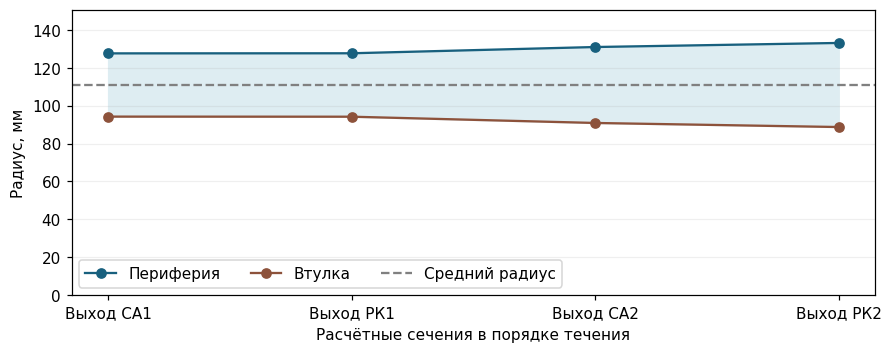

In [177]:
fig = plt.figure(figsize=(8, 3.1), constrained_layout=True)
ax = fig.subplots()
ax.fill_between(plane_names, r_hub, r_tip, color="#deedf2")
ax.plot(plane_names, r_tip, "o-", color="#18607e", label="Периферия")
ax.plot(plane_names, r_hub, "o-", color="#8d523b", label="Втулка")
ax.axhline(1000*D/2, color="gray", linestyle="--", label="Средний радиус")
ax.set(ylabel="Радиус, мм", xlabel="Расчётные сечения в порядке течения", ylim=(0, 1.13*max(r_tip)))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="lower left", ncol=3)
plt.show()

### 6.1. Втулка, средний радиус и периферия

Используем закон свободного вихря и постоянную осевую составляющую по высоте. Для каждого венца расчёт выполнен в 201 точке. В выводе отдельного шага показан пример у втулки за СА I, затем приведены сводные таблицы трёх высот. Индекс ξ задаёт долю высоты лопатки.

**Координаты расчётных точек по относительной высоте**

$$
\xi_j=j/200,\qquad 0\leqslant j\leqslant 200
$$

In [178]:
span_grid = np.linspace(0, 1, 201)
print("Расчётные точки по относительной высоте:", len(span_grid))

Расчётные точки по относительной высоте: 201


**Местный радиус**

$$
r=D_m/2+(\xi-1/2)l
$$

In [179]:
r_sa1 = D / 2 + (span_grid - 0.5) * l1_1
r_rk1 = D / 2 + (span_grid - 0.5) * l2_1
r_sa2 = D / 2 + (span_grid - 0.5) * l1_2
r_rk2 = D / 2 + (span_grid - 0.5) * l2_2
print(f"СА I, втулка: {r_sa1[0] * 1000:.5f} мм")

СА I, втулка: 94.18672 мм


**Осевая скорость по высоте**

$$
c_a(r)=c_{am}
$$

In [180]:
ca_sa1 = np.full_like(span_grid, ca1_1)
ca_rk1 = np.full_like(span_grid, ca2_1)
ca_sa2 = np.full_like(span_grid, ca1_2)
ca_rk2 = np.full_like(span_grid, ca2_2)
print(f"СА I, втулка: {ca_sa1[0]:.5f} м/с")

СА I, втулка: 144.83803 м/с


**Окружная составляющая абсолютной скорости**

$$
c_u(r)=c_{um}D_m/(2r)
$$

In [181]:
cu_sa1 = cu1_1 * D / (2 * r_sa1)
cu_rk1 = cu2_1 * D / (2 * r_rk1)
cu_sa2 = cu1_2 * D / (2 * r_sa2)
cu_rk2 = cu2_2 * D / (2 * r_rk2)
print(f"СА I, втулка: {cu_sa1[0]:.5f} м/с")

СА I, втулка: 524.69683 м/с


**Окружная скорость колеса**

$$
u(r)=2\pi nr/60
$$

In [182]:
u_sa1 = 2 * math.pi * n * r_sa1 / 60
u_rk1 = 2 * math.pi * n * r_rk1 / 60
u_sa2 = 2 * math.pi * n * r_sa2 / 60
u_rk2 = 2 * math.pi * n * r_rk2 / 60
print(f"СА I, втулка: {u_sa1[0]:.5f} м/с")

СА I, втулка: 295.89632 м/с


**Окружная составляющая относительной скорости**

$$
w_u(r)=c_u(r)-u(r)
$$

In [183]:
wu_sa1 = cu_sa1 - u_sa1
wu_rk1 = cu_rk1 - u_rk1
wu_sa2 = cu_sa2 - u_sa2
wu_rk2 = cu_rk2 - u_rk2
print(f"СА I, втулка: {wu_sa1[0]:.5f} м/с")

СА I, втулка: 228.80051 м/с


**Модуль абсолютной скорости**

$$
c(r)=\sqrt{c_a^2+c_u^2}
$$

In [184]:
c_sa1 = np.hypot(ca_sa1, cu_sa1)
c_rk1 = np.hypot(ca_rk1, cu_rk1)
c_sa2 = np.hypot(ca_sa2, cu_sa2)
c_rk2 = np.hypot(ca_rk2, cu_rk2)
print(f"СА I, втулка: {c_sa1[0]:.5f} м/с")

СА I, втулка: 544.32051 м/с


**Модуль относительной скорости**

$$
w(r)=\sqrt{c_a^2+w_u^2}
$$

In [185]:
w_sa1 = np.hypot(ca_sa1, wu_sa1)
w_rk1 = np.hypot(ca_rk1, wu_rk1)
w_sa2 = np.hypot(ca_sa2, wu_sa2)
w_rk2 = np.hypot(ca_rk2, wu_rk2)
print(f"СА I, втулка: {w_sa1[0]:.5f} м/с")

СА I, втулка: 270.79093 м/с


**Статическая температура**

$$
T(r)=T_m+[c_{um}^2-c_u(r)^2]/(2c_p)
$$

In [186]:
T_sa1 = T1_1 + (cu1_1**2 - cu_sa1**2) / (2 * cp_1)
T_rk1 = T2_1 + (cu2_1**2 - cu_rk1**2) / (2 * cp_1)
T_sa2 = T1_2 + (cu1_2**2 - cu_sa2**2) / (2 * cp_2)
T_rk2 = T2_2 + (cu2_2**2 - cu_rk2**2) / (2 * cp_2)
print(f"СА I, втулка: {T_sa1[0]:.5f} К")

СА I, втулка: 1040.41497 К


**Статическое давление**

$$
p(r)=p_m[T(r)/T_m]^{c_p/R}
$$

In [187]:
p_sa1 = p1_1 * (T_sa1 / T1_1)**(cp_1 / R)
p_rk1 = p2_1 * (T_rk1 / T2_1)**(cp_1 / R)
p_sa2 = p1_2 * (T_sa2 / T1_2)**(cp_2 / R)
p_rk2 = p2_2 * (T_rk2 / T2_2)**(cp_2 / R)
print(f"СА I, втулка: {p_sa1[0] / 1000:.5f} кПа")

СА I, втулка: 207.02805 кПа


**Местная скорость звука**

$$
a(r)=\sqrt{kRT(r)},\quad k=c_p/(c_p-R)
$$

In [188]:
a_sa1 = np.sqrt((cp_1 / (cp_1 - R)) * R * T_sa1)
a_rk1 = np.sqrt((cp_1 / (cp_1 - R)) * R * T_rk1)
a_sa2 = np.sqrt((cp_2 / (cp_2 - R)) * R * T_sa2)
a_rk2 = np.sqrt((cp_2 / (cp_2 - R)) * R * T_rk2)
print(f"СА I, втулка: {a_sa1[0]:.5f} м/с")

СА I, втулка: 626.56291 м/с


**Число Маха абсолютной скорости**

$$
M_c=c/a
$$

In [189]:
Mc_sa1 = c_sa1 / a_sa1
Mc_rk1 = c_rk1 / a_rk1
Mc_sa2 = c_sa2 / a_sa2
Mc_rk2 = c_rk2 / a_rk2
print(f"СА I, втулка: {Mc_sa1[0]:.5f}")

СА I, втулка: 0.86874


**Число Маха относительной скорости**

$$
M_w=w/a
$$

In [190]:
Mw_sa1 = w_sa1 / a_sa1
Mw_rk1 = w_rk1 / a_rk1
Mw_sa2 = w_sa2 / a_sa2
Mw_rk2 = w_rk2 / a_rk2
print(f"СА I, втулка: {Mw_sa1[0]:.5f}")

СА I, втулка: 0.43218


**Угол абсолютной скорости**

Знак s равен +1 на входе РК и −1 на выходе. Функция atan2 определяет четверть.

$$
\alpha=\operatorname{atan2}(c_a,s c_u)
$$

In [191]:
alpha_deg_sa1 = np.degrees(np.arctan2(ca_sa1, cu_sa1))
alpha_deg_rk1 = np.degrees(np.arctan2(ca_rk1, -cu_rk1))
alpha_deg_sa2 = np.degrees(np.arctan2(ca_sa2, cu_sa2))
alpha_deg_rk2 = np.degrees(np.arctan2(ca_rk2, -cu_rk2))
print(f"СА I, втулка: {alpha_deg_sa1[0]:.5f} °")

СА I, втулка: 15.43171 °


**Угол относительной скорости**

$$
\beta=\operatorname{atan2}(c_a,s w_u)
$$

In [192]:
beta_deg_sa1 = np.degrees(np.arctan2(ca_sa1, wu_sa1))
beta_deg_rk1 = np.degrees(np.arctan2(ca_rk1, -wu_rk1))
beta_deg_sa2 = np.degrees(np.arctan2(ca_sa2, wu_sa2))
beta_deg_rk2 = np.degrees(np.arctan2(ca_rk2, -wu_rk2))
print(f"СА I, втулка: {beta_deg_sa1[0]:.5f} °")

СА I, втулка: 32.33512 °


**Местная степень реактивности**

$$
\rho_{\rm ст}(\xi)=1-\frac{1-[p_1(\xi)/p_0^*]^{R/c_p}}{1-[p_2(\xi)/p_0^*]^{R/c_p}}
$$

In [193]:
Hc_rel_1 = 1 - (p_sa1 / p0t_1)**(R / cp_1)
H_rel_1 = 1 - (p_rk1 / p0t_1)**(R / cp_1)
reaction_span_1 = 1 - Hc_rel_1 / H_rel_1
Hc_rel_2 = 1 - (p_sa2 / p0t_2)**(R / cp_2)
H_rel_2 = 1 - (p_rk2 / p0t_2)**(R / cp_2)
reaction_span_2 = 1 - Hc_rel_2 / H_rel_2
print(f"Ступень I, втулка: реактивность = {reaction_span_1[0]:.5f}")

Ступень I, втулка: реактивность = 0.14264


**Местная работа Эйлера**

$$
L_u(\xi)=u_1c_{1u}-u_2c_{2u}
$$

In [194]:
Lu_span_1 = u_sa1 * cu_sa1 - u_rk1 * cu_rk1
Lu_span_2 = u_sa2 * cu_sa2 - u_rk2 * cu_rk2
print(f"Ступень I, втулка: Lᵤ = {Lu_span_1[0] / 1000:.3f} кДж/кг")

Ступень I, втулка: Lᵤ = 155.256 кДж/кг


**Сводные таблицы по трём высотам.** Сечение выхода из СА совпадает со входом в РК. Скорости приведены в м/с.

In [195]:
span_names = ["Втулка", "Середина", "Периферия"]
span_indices = [0, 100, 200]
speed_rows = []
thermal_rows = []
for h in range(3):
    j = span_indices[h]
    speed_rows.append([1, span_names[h], "Вход", 2000 * r_sa1[j],
                       u_sa1[j], cu_sa1[j], ca_sa1[j], wu_sa1[j], c_sa1[j], w_sa1[j],
                       alpha_deg_sa1[j], beta_deg_sa1[j], Mc_sa1[j], Mw_sa1[j], reaction_span_1[j]])
    speed_rows.append([1, span_names[h], "Выход", 2000 * r_rk1[j],
                       u_rk1[j], cu_rk1[j], ca_rk1[j], wu_rk1[j], c_rk1[j], w_rk1[j],
                       alpha_deg_rk1[j], beta_deg_rk1[j], Mc_rk1[j], Mw_rk1[j], reaction_span_1[j]])
    thermal_rows.append([1, span_names[h], T_sa1[j], p_sa1[j] / 1000,
                         T_rk1[j], p_rk1[j] / 1000, reaction_span_1[j], Lu_span_1[j] / 1000])
    speed_rows.append([2, span_names[h], "Вход", 2000 * r_sa2[j],
                       u_sa2[j], cu_sa2[j], ca_sa2[j], wu_sa2[j], c_sa2[j], w_sa2[j],
                       alpha_deg_sa2[j], beta_deg_sa2[j], Mc_sa2[j], Mw_sa2[j], reaction_span_2[j]])
    speed_rows.append([2, span_names[h], "Выход", 2000 * r_rk2[j],
                       u_rk2[j], cu_rk2[j], ca_rk2[j], wu_rk2[j], c_rk2[j], w_rk2[j],
                       alpha_deg_rk2[j], beta_deg_rk2[j], Mc_rk2[j], Mw_rk2[j], reaction_span_2[j]])
    thermal_rows.append([2, span_names[h], T_sa2[j], p_sa2[j] / 1000,
                         T_rk2[j], p_rk2[j] / 1000, reaction_span_2[j], Lu_span_2[j] / 1000])
speeds = pd.DataFrame(speed_rows, columns=["Ст.", "Высота", "РК", "D, мм", "u", "cᵤ", "cₐ=wₐ", "wᵤ",
                                           "c", "w", "α, °", "β, °", "M(c)", "M(w)", "ρст"])
thermal = pd.DataFrame(thermal_rows, columns=["Ст.", "Высота", "T₁, К", "p₁, кПа", "T₂, К", "p₂, кПа", "ρст", "Lᵤ, кДж/кг"])
speeds = speeds.sort_values("Ст.", kind="stable").reset_index(drop=True)
thermal = thermal.sort_values("Ст.", kind="stable").reset_index(drop=True)
print("Скорости в м/с, диаметры в мм. Вход РК совпадает с выходом СА.")
display(speeds.set_index(["Ст.", "Высота", "РК"]).round(3), thermal.set_index(["Ст.", "Высота"]).round(3))

Скорости в м/с, диаметры в мм. Вход РК совпадает с выходом СА.


D, мм        u       cᵤ  ...   M(c)   M(w)    ρст
Ст. Высота    РК                                ...                     
1   Втулка    Вход   188.373  295.896  524.697  ...  0.869  0.432  0.143
              Выход  188.275  295.742   -0.000  ...  0.275  0.550  0.143
    Середина  Вход   221.729  348.290  445.766  ...  0.737  0.274  0.350
              Выход  221.729  348.290   -0.000  ...  0.275  0.625  0.350
    Периферия Вход   255.084  400.684  387.477  ...  0.644  0.227  0.481
              Выход  255.182  400.839   -0.000  ...  0.275  0.701  0.481
2   Втулка    Вход   181.669  285.365  495.173  ...  0.894  0.473  0.199
              Выход  177.383  278.632  -26.790  ...  0.362  0.636  0.199
    Середина  Вход   221.729  348.290  405.711  ...  0.741  0.322  0.415
              Выход  221.729  348.290  -21.432  ...  0.361  0.729  0.415
    Периферия Вход   261.788  411.215  343.628  ...  0.642  0.324  0.540
              Выход  266.074  417.948  -17.860  ...  0.361  0.830  0.540

[12 rows x 12 columns]

T₁, К  p₁, кПа     T₂, К  p₂, кПа    ρст  Lᵤ, кДж/кг
Ст. Высота                                                            
1   Втулка     1040.415  207.028  1022.423  189.390  0.143     155.256
    Середина   1072.176  234.868  1022.423  189.390  0.350     155.256
    Периферия  1092.315  253.941  1022.423  189.390  0.481     155.256
2   Втулка      919.406  117.302   892.828  101.758  0.199     148.770
    Середина    953.577  136.249   892.937  101.809  0.415     148.770
    Периферия   973.302  148.190   892.997  101.837  0.540     148.770

### 6.2. Треугольники скоростей

По горизонтали откладываем окружную скорость, по вертикали — осевую. Точки $O=(0,0)$, $U=(u,0)$ и $C=(c_u,c_a)$ задают векторы $\overrightarrow{OU}=\vec u$, $\overrightarrow{UC}=\vec w$ и $\overrightarrow{OC}=\vec c$. Для неподвижного СА $U=O$. Масштаб осей одинаков.

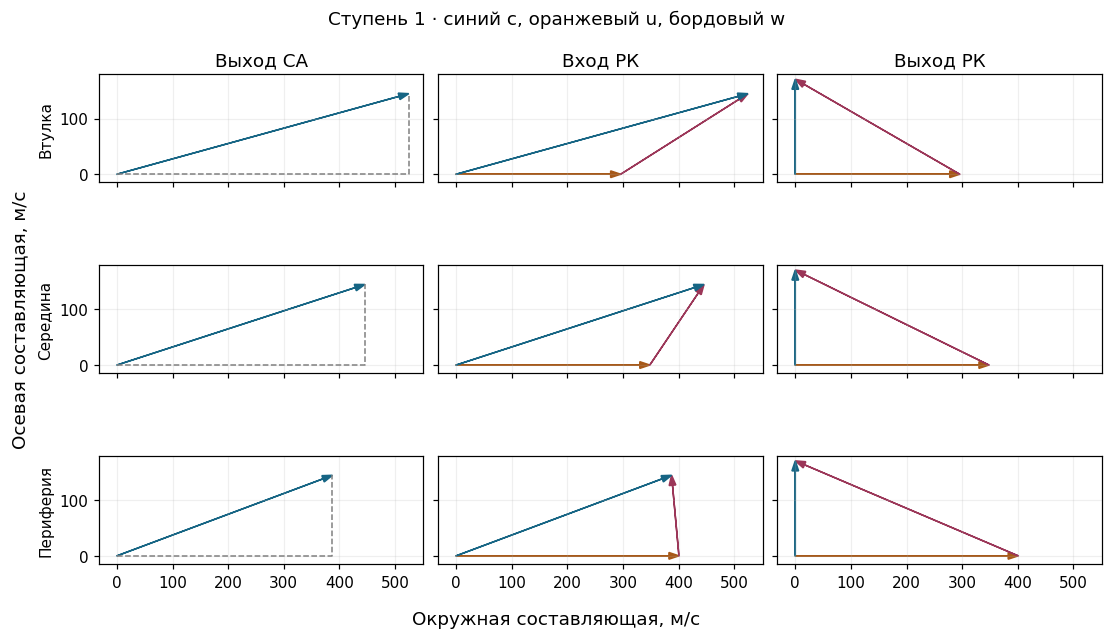

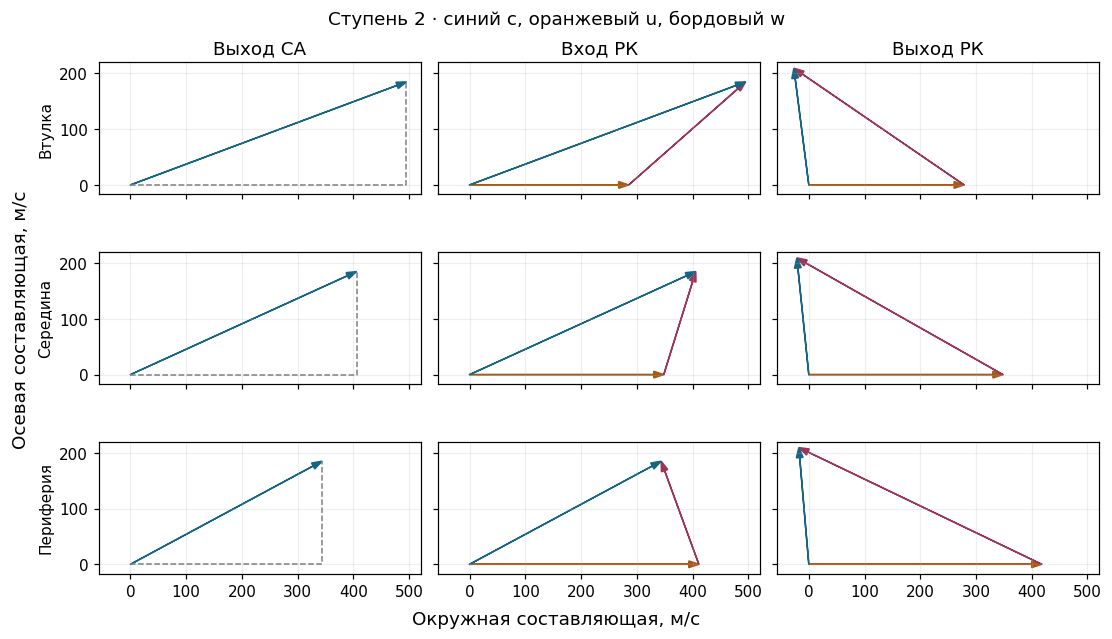

In [196]:
for stage_number in [1, 2]:
    fig = plt.figure(figsize=(10, 5.7), constrained_layout=True)
    axes = fig.subplots(3, 3, sharex=True, sharey=True)
    for row_number in range(3):
        j = span_indices[row_number]
        for col in range(3):
            ax = axes[row_number, col]
            if stage_number == 1 and col < 2:
                tangential = cu_sa1[j]
                axial = ca_sa1[j]
                wheel_speed = u_sa1[j]
            elif stage_number == 1:
                tangential = cu_rk1[j]
                axial = ca_rk1[j]
                wheel_speed = u_rk1[j]
            elif col < 2:
                tangential = cu_sa2[j]
                axial = ca_sa2[j]
                wheel_speed = u_sa2[j]
            else:
                tangential = cu_rk2[j]
                axial = ca_rk2[j]
                wheel_speed = u_rk2[j]
            if col == 0:
                ax.plot([0, tangential, tangential], [0, 0, axial], "--", color="gray", lw=1)
            else:
                ax.arrow(0, 0, wheel_speed, 0, color="#a75817", head_width=12, length_includes_head=True)
                ax.arrow(wheel_speed, 0, tangential-wheel_speed, axial, color="#9b3658", head_width=12, length_includes_head=True)
            ax.arrow(0, 0, tangential, axial, color="#166584", head_width=12, length_includes_head=True)
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.2)
            if row_number == 0:
                ax.set_title(["Выход СА", "Вход РК", "Выход РК"][col])
            if col == 0:
                ax.set_ylabel(span_names[row_number])
    fig.suptitle(f"Ступень {stage_number} · синий c, оранжевый u, бордовый w")
    fig.supxlabel("Окружная составляющая, м/с")
    fig.supylabel("Осевая составляющая, м/с")
    plt.show()

### 6.3. Предварительные профили четырёх венцов

Направления входной и выходной касательных берутся из треугольников скоростей. Для СА I принят осевой вход. Углы атаки и отклонения в этом приближении равны нулю. Координаты профилей в мм.

**Направления потока для построения профиля**

$$
\boldsymbol v_{\rm СА}=(c_a,c_u),\qquad \boldsymbol v_{\rm РК}=(c_a,w_u)
$$

In [197]:
# По три высоты для каждого венца. Порядок венцов: СА I, РК I, СА II, РК II.
profile_count = 12
idx = span_indices
profile_stage = [1]*6 + [2]*6
profile_row = ["СА"]*3 + ["РК"]*3 + ["СА"]*3 + ["РК"]*3
profile_height = span_names * 4

# Для СА I известна только осевая ориентация входа. Единичный вектор задаёт направление.
inlet_axial = np.concatenate([np.ones(3), ca_sa1[idx], ca_rk1[idx], ca_sa2[idx]])
inlet_tangential = np.concatenate([np.zeros(3), wu_sa1[idx], cu_rk1[idx], wu_sa2[idx]])
outlet_axial = np.concatenate([ca_sa1[idx], ca_rk1[idx], ca_sa2[idx], ca_rk2[idx]])
outlet_tangential = np.concatenate([cu_sa1[idx], wu_rk1[idx], cu_sa2[idx], wu_rk2[idx]])
inlet_radius = np.concatenate([r_sa1[idx], r_sa1[idx], r_rk1[idx], r_sa2[idx]])
outlet_radius = np.concatenate([r_sa1[idx], r_rk1[idx], r_sa2[idx], r_rk2[idx]])
print("Сечений профилей:", profile_count)

Сечений профилей: 12


**Осевая ширина профиля**

$$
b_{\rm СА}=l_1/2,\qquad b_{\rm РК}=l_2/2{,}5
$$

In [198]:
b_sa1 = 1000 * l1_1 / 2
b_rk1 = 1000 * l2_1 / 2.5
b_sa2 = 1000 * l1_2 / 2
b_rk2 = 1000 * l2_2 / 2.5
blade_width = np.repeat([b_sa1, b_rk1, b_sa2, b_rk2], 3)
print(f"Осевая ширина профиля СА I = {b_sa1:.3f} мм")

Осевая ширина профиля СА I = 16.678 мм


**Число лопаток в венце**

$$
Z=\max(1,\operatorname{round}[\pi D_m/(b\,(t_m/b))])
$$

In [199]:
blade_count = []
for width in blade_width:
    number = round(1000 * math.pi * D / (pitch_ratio * width))
    blade_count.append(max(1, number))
print("Число лопаток СА I:", blade_count[0])

Число лопаток СА I: 51


**Местный шаг решётки**

$$
t=\pi(r_{\rm вх}+r_{\rm вых})/Z
$$

In [200]:
blade_pitch = 1000 * math.pi * (inlet_radius + outlet_radius) / blade_count
print(f"Шаг СА I на среднем радиусе = {blade_pitch[1]:.3f} мм")

Шаг СА I на среднем радиусе = 13.658 мм


**Единичная касательная на входе**

$$
\boldsymbol e_1=\boldsymbol v_{\rm вх}/|\boldsymbol v_{\rm вх}|
$$

In [201]:
vector_length_in = np.hypot(inlet_axial, inlet_tangential)
unit_in_x = inlet_axial / vector_length_in
unit_in_y = inlet_tangential / vector_length_in
print(f"СА I, середина: ({unit_in_x[1]:.4f}, {unit_in_y[1]:.4f})")

СА I, середина: (1.0000, 0.0000)


**Единичная касательная на выходе**

$$
\boldsymbol e_2=\boldsymbol v_{\rm вых}/|\boldsymbol v_{\rm вых}|
$$

In [202]:
vector_length_out = np.hypot(outlet_axial, outlet_tangential)
unit_out_x = outlet_axial / vector_length_out
unit_out_y = outlet_tangential / vector_length_out
print(f"СА I, середина: ({unit_out_x[1]:.4f}, {unit_out_y[1]:.4f})")

СА I, середина: (0.3090, 0.9511)


**Углы касательных от оси**

$$
\theta_j=\operatorname{atan2}(e_{ju},e_{ja}),\quad j=1,2
$$

In [203]:
theta_in = np.arctan2(unit_in_y, unit_in_x)
theta_out = np.arctan2(unit_out_y, unit_out_x)
print(f"СА I, середина: вход {np.degrees(theta_in[1]):.3f}°, выход {np.degrees(theta_out[1]):.3f}°")

СА I, середина: вход 0.000°, выход 72.000°


**Угол установки предварительного профиля**

$$
\gamma=(\theta_1+\theta_2)/2
$$

In [204]:
profile_angle = (theta_in + theta_out) / 2
print(f"Угол установки СА I на среднем радиусе = {np.degrees(profile_angle[1]):.3f}°")

Угол установки СА I на среднем радиусе = 36.000°


**Опорные точки кривой Безье**

$$
P_0=(0,0),\quad P_3=b(1,\tan\gamma),\quad P_1=P_0+0{,}4b\boldsymbol e_1,\quad P_2=P_3-0{,}4b\boldsymbol e_2
$$

In [205]:
P0_x = np.zeros(profile_count)
P0_y = np.zeros(profile_count)
P3_x = blade_width
P3_y = blade_width * np.tan(profile_angle)
P1_x = P0_x + 0.4 * blade_width * unit_in_x
P1_y = P0_y + 0.4 * blade_width * unit_in_y
P2_x = P3_x - 0.4 * blade_width * unit_out_x
P2_y = P3_y - 0.4 * blade_width * unit_out_y
print("Контрольные точки СА I на среднем радиусе, мм:")
print("x =", np.round([P0_x[1], P1_x[1], P2_x[1], P3_x[1]], 3))
print("y =", np.round([P0_y[1], P1_y[1], P2_y[1], P3_y[1]], 3))

Контрольные точки СА I на среднем радиусе, мм:
x = [ 0.     6.671 14.616 16.678]
y = [ 0.     0.     5.772 12.117]


**Координаты средней линии профиля**

$$
B(t)=(1-t)^3P_0+3(1-t)^2tP_1+3(1-t)t^2P_2+t^3P_3
$$

In [206]:
t_curve = np.linspace(0, 1, 121)
point_count = len(t_curve)
middle = point_count // 2
mid_x = np.zeros((profile_count, point_count))
mid_y = np.zeros((profile_count, point_count))
for j in range(profile_count):
    t = t_curve
    mid_x[j] = (1-t)**3 * P0_x[j] + 3*(1-t)**2*t * P1_x[j] + 3*(1-t)*t**2 * P2_x[j] + t**3 * P3_x[j]
    mid_y[j] = (1-t)**3 * P0_y[j] + 3*(1-t)**2*t * P1_y[j] + 3*(1-t)*t**2 * P2_y[j] + t**3 * P3_y[j]
print(f"Середина кривой СА I: ({mid_x[1, middle]:.3f}, {mid_y[1, middle]:.3f}) мм")

Середина кривой СА I: (10.067, 3.679) мм


**Единичная нормаль к средней линии**

$$
\boldsymbol n=(-B_y\prime,B_x\prime)/|B\prime|
$$

In [207]:
normal_x = np.zeros_like(mid_x)
normal_y = np.zeros_like(mid_y)
for j in range(profile_count):
    t = t_curve
    dx = 3 * ((1-t)**2*(P1_x[j]-P0_x[j]) + 2*(1-t)*t*(P2_x[j]-P1_x[j]) + t**2*(P3_x[j]-P2_x[j]))
    dy = 3 * ((1-t)**2*(P1_y[j]-P0_y[j]) + 2*(1-t)*t*(P2_y[j]-P1_y[j]) + t**2*(P3_y[j]-P2_y[j]))
    tangent_length = np.hypot(dx, dy)
    normal_x[j] = -dy / tangent_length
    normal_y[j] = dx / tangent_length
print(f"Нормаль в середине: ({normal_x[1, middle]:.3f}, {normal_y[1, middle]:.3f})")

Нормаль в середине: (-0.588, 0.809)


**Распределение толщины вдоль профиля**

$$
h(X)=0{,}2969\sqrt X-0{,}126X-0{,}3516X^2+0{,}2843X^3-0{,}1036X^4,\quad X=B_x/b
$$

In [208]:
relative_x = np.zeros_like(mid_x)
thickness_shape = np.zeros_like(mid_x)
for j in range(profile_count):
    X = mid_x[j] / blade_width[j]
    relative_x[j] = X
    thickness_shape[j] = 0.2969*np.sqrt(X) - 0.126*X - 0.3516*X**2 + 0.2843*X**3 - 0.1036*X**4
print(f"Максимум закона толщины, СА I: {thickness_shape[1].max():.6f}")

Максимум закона толщины, СА I: 0.100010


**Полутолщина профиля**

$$
d(X)=\frac{b}{2}(d_{\max}/b)\,h(X)/\max h
$$

In [209]:
half_thickness = np.zeros_like(mid_x)
for j in range(profile_count):
    half_thickness[j] = 0.5 * blade_width[j] * thickness * thickness_shape[j] / thickness_shape[j].max()
print(f"Максимальная полутолщина СА I на среднем радиусе = {half_thickness[1].max():.4f} мм")

Максимальная полутолщина СА I на среднем радиусе = 0.8339 мм


**Замкнутый контур профиля**

$$
\boldsymbol P_{\pm}=B(t)-B(0{,}5)\ \pm d(X)\boldsymbol n
$$

In [210]:
contour_points = 2 * point_count - 1
contour_x = np.zeros((profile_count, contour_points))
contour_y = np.zeros((profile_count, contour_points))
contour_station = np.zeros((profile_count, contour_points))
for j in range(profile_count):
    x_centered = mid_x[j] - mid_x[j, middle]
    y_centered = mid_y[j] - mid_y[j, middle]
    offset_x = half_thickness[j] * normal_x[j]
    offset_y = half_thickness[j] * normal_y[j]
    x_side_a = x_centered + offset_x
    x_side_b = x_centered - offset_x
    y_side_a = y_centered + offset_y
    y_side_b = y_centered - offset_y
    # Обходим вторую сторону в обратном направлении, не дублируя заднюю кромку.
    contour_x[j] = np.concatenate([x_side_a, np.flip(x_side_b[:-1])])
    contour_y[j] = np.concatenate([y_side_a, np.flip(y_side_b[:-1])])
    contour_station[j] = np.concatenate([relative_x[j], np.flip(relative_x[j, :-1])])
print("Точек в одном контуре:", contour_points)

Точек в одном контуре: 241


**Радиусы точек контура**

$$
r(X)=r_{\rm вх}+(r_{\rm вых}-r_{\rm вх})X
$$

In [211]:
contour_radius = np.zeros_like(contour_x)
for j in range(profile_count):
    contour_radius[j] = 1000 * (inlet_radius[j] + (outlet_radius[j] - inlet_radius[j]) * contour_station[j])
print(f"СА I, начало контура на среднем радиусе: r = {contour_radius[1, 0]:.3f} мм")

СА I, начало контура на среднем радиусе: r = 110.864 мм


**Графики и координаты профилей.** Для рабочего профиля ещё проверяют горло, форму кромок и потери решётки.

b, мм   Z  Шаг, мм  Установка, °  Вход, °  Выход, °
Ст. Венец Высота                                                         
1   СА    Втулка     16.678  51   11.604        37.284    0.000    74.568
          Середина   16.678  51   13.658        36.000    0.000    72.000
          Периферия  16.678  51   15.713        34.752    0.000    69.504
    РК    Втулка     13.381  63    9.391        -1.165   57.665   -59.995
          Середина   13.381  63   11.057       -14.970   33.940   -63.880
          Периферия  13.381  63   12.723       -36.067   -5.210   -66.923
2   СА    Втулка     20.030  42   13.836        34.762   -0.000    69.525
          Середина   20.030  42   16.585        32.750   -0.000    65.500
          Периферия  20.030  42   19.335        30.859   -0.000    61.717
    РК    Втулка     17.738  48   11.750        -3.483   48.612   -55.577
          Середина   17.738  48   14.512       -21.616   17.253   -60.485
          Периферия  17.738  48   17.274       -42.213  -20.080   -64.346

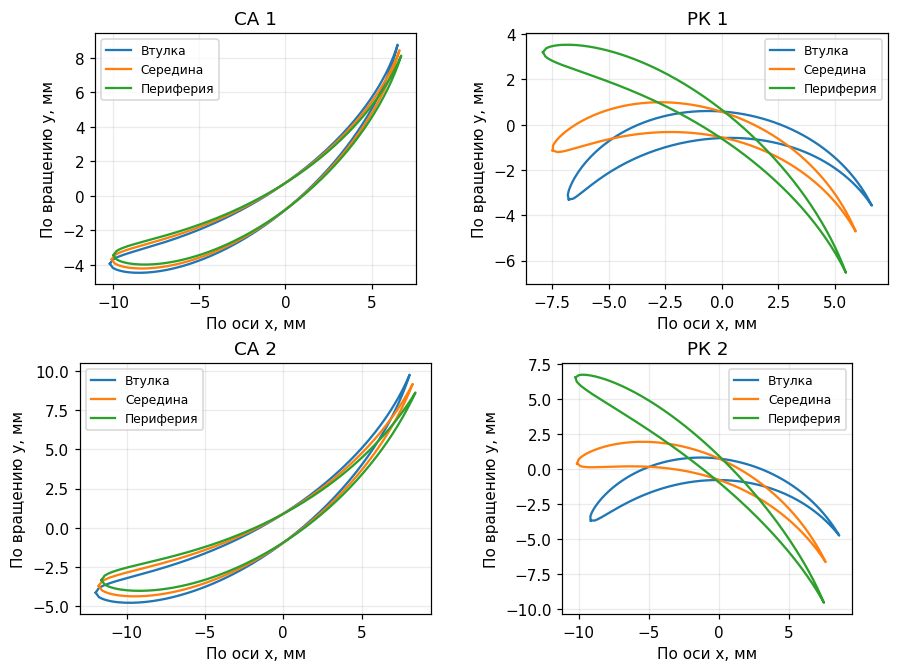

In [212]:
geometry = pd.DataFrame()
geometry["Ст."] = profile_stage
geometry["Венец"] = profile_row
geometry["Высота"] = profile_height
geometry["b, мм"] = blade_width
geometry["Z"] = blade_count
geometry["Шаг, мм"] = blade_pitch
geometry["Установка, °"] = np.degrees(profile_angle)
geometry["Вход, °"] = np.degrees(theta_in)
geometry["Выход, °"] = np.degrees(theta_out)
display(geometry.set_index(["Ст.", "Венец", "Высота"]).round(3))

profile_xyz = pd.DataFrame()
profile_xyz["Ст."] = np.repeat(profile_stage, contour_points)
profile_xyz["Венец"] = np.repeat(profile_row, contour_points)
profile_xyz["Высота"] = np.repeat(profile_height, contour_points)
profile_xyz["Точка"] = np.tile(np.arange(contour_points), profile_count)
profile_xyz["x, мм"] = contour_x.flatten()
profile_xyz["y, мм"] = contour_y.flatten()
profile_xyz["r, мм"] = contour_radius.flatten()
# Сохранение точек при необходимости:
# profile_xyz.to_csv("profiles_12_sections.csv", index=False, sep=";", encoding="utf-8-sig")

fig = plt.figure(figsize=(8.3, 6), constrained_layout=True)
axes = fig.subplots(2, 2)
for j in range(profile_count):
    stage_index = profile_stage[j] - 1
    if profile_row[j] == "СА":
        ax = axes[stage_index, 0]
    else:
        ax = axes[stage_index, 1]
    ax.plot(contour_x[j], contour_y[j], label=profile_height[j])
    ax.set(title=f"{profile_row[j]} {stage_index + 1}", xlabel="По оси x, мм", ylabel="По вращению y, мм", aspect="equal")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

<a id="variants"></a>
## Приложение А. Сопоставление и контроль расчёта

Варианты выходного сопла сведены в одну таблицу в [§ 5](#nozzle).

### Энергия, потери и проверка расхода

Проверяем результат по каждой ступени. Статическая температура основного потока используется в уравнении неразрывности. Отдельно вычисляем невязку при подстановке скорректированной температуры за РК.

**Потери в СА**

$$
h_{\rm с}=(\varphi^{-2}-1)c_1^2/2
$$

In [213]:
hc_1 = (1 / phi_I**2 - 1) * c1_1**2 / 2
hc_2 = (1 / phi_II**2 - 1) * c1_2**2 / 2
print(f"Ступень 1: {hc_1 / 1000:.4f} кДж/кг")
print(f"Ступень 2: {hc_2 / 1000:.4f} кДж/кг")

Ступень 1: 9.3442 кДж/кг
Ступень 2: 8.4553 кДж/кг


**Потери в РК**

$$
h_{\rm л}=(\psi^{-2}-1)w_2^2/2
$$

In [214]:
hl_1 = (1 / psi_I**2 - 1) * w2_1**2 / 2
hl_2 = (1 / psi_II**2 - 1) * w2_2**2 / 2
print(f"Ступень 1: {hl_1 / 1000:.4f} кДж/кг")
print(f"Ступень 2: {hl_2 / 1000:.4f} кДж/кг")

Ступень 1: 4.6488 кДж/кг
Ступень 2: 5.5766 кДж/кг


**Потеря СА, приведённая к выходу ступени**

$$
h_{\rm с,пр}=h_{\rm с}T_2/T_1
$$

In [215]:
hc_out_1 = hc_1 * T2_1 / T1_1
hc_out_2 = hc_2 * T2_2 / T1_2
print(f"Ступень 1: {hc_out_1 / 1000:.4f} кДж/кг")
print(f"Ступень 2: {hc_out_2 / 1000:.4f} кДж/кг")

Ступень 1: 8.9106 кДж/кг
Ступень 2: 7.9176 кДж/кг


**Кинетическая энергия выходящего газа**

$$
h_{\rm в}=c_2^2/2
$$

In [216]:
hv_1 = c2_1**2 / 2
hv_2 = c2_2**2 / 2
print(f"Ступень 1: {hv_1 / 1000:.4f} кДж/кг")
print(f"Ступень 2: {hv_2 / 1000:.4f} кДж/кг")

Ступень 1: 14.5826 кДж/кг
Ступень 2: 22.1346 кДж/кг


**Невязка по изменению полной энтальпии**

$$
\Delta h=c_p(T_0^*-T_{\rm вых}^*)-L
$$

In [217]:
dh_1 = cp_1 * (T0t_1 - T2t_1) - L_1
dh_2 = cp_2 * (T0t_2 - T2t_2) - L_2
print(f"Ступень 1: {dh_1:.4f} Дж/кг")
print(f"Ступень 2: {dh_2:.4f} Дж/кг")

Ступень 1: 0.0000 Дж/кг
Ступень 2: 0.0000 Дж/кг


**Невязка баланса потерь**

$$
\Delta H=H-(h_{\rm с,пр}+h_{\rm л}+h_{\rm в}+L_u)
$$

In [218]:
dH_1 = H_1 - hc_out_1 - hl_1 - hv_1 - Lu_1
dH_2 = H_2 - hc_out_2 - hl_2 - hv_2 - Lu_2
print(f"Ступень 1: {dH_1:.4f} Дж/кг")
print(f"Ступень 2: {dH_2:.4f} Дж/кг")

Ступень 1: -33.5982 Дж/кг
Ступень 2: -41.9309 Дж/кг


**Расход с температурной поправкой**

$$
G_{\rm гор}=\pi D_m l_2 c_{2a}p_2/(RT'_2)
$$

In [219]:
Ghot_1 = math.pi * D * l2_1 * ca2_1 * p2_1 / (R * T2_corr_1)
Ghot_2 = math.pi * D * l2_2 * ca2_2 * p2_2 / (R * T2_corr_2)
print(f"Ступень 1: {Ghot_1:.4f} кг/с")
print(f"Ступень 2: {Ghot_2:.4f} кг/с")

Ступень 1: 2.5566 кг/с
Ступень 2: 2.5574 кг/с


**Относительная невязка расхода с поправкой**

$$
\varepsilon_G=100(G_{\rm гор}/G_{\rm г}-1)
$$

In [220]:
Ghot_err_1 = 100 * (Ghot_1 / G - 1)
Ghot_err_2 = 100 * (Ghot_2 / G - 1)
print(f"Ступень 1: {Ghot_err_1:.4f} %")
print(f"Ступень 2: {Ghot_err_2:.4f} %")

Ступень 1: -0.3261 %
Ступень 2: -0.2974 %


**Теплоперепад ступени по полным параметрам**

$$
H^*=c_pT_0^*[1-(p_{\rm вых}^*/p_0^*)^{R/c_p}]
$$

In [221]:
Hstar_1 = cp_1 * T0t_1 * (1 - (p2t_1 / p0t_1)**(R / cp_1))
Hstar_2 = cp_2 * T0t_2 * (1 - (p2t_2 / p0t_2)**(R / cp_2))
print(f"Ступень 1: {Hstar_1 / 1000:.4f} кДж/кг")
print(f"Ступень 2: {Hstar_2 / 1000:.4f} кДж/кг")

Ступень 1: 168.9887 кДж/кг
Ступень 2: 162.5699 кДж/кг


**КПД на окружности**

$$
\eta_u=L_u/H
$$

In [222]:
eta_u_1 = Lu_1 / H_1
eta_u_2 = Lu_2 / H_2
print(f"Ступень 1: {eta_u_1:.4f}")
print(f"Ступень 2: {eta_u_2:.4f}")

Ступень 1: 0.8467
Ступень 2: 0.8070


**Мощностной КПД ступени**

$$
\eta_{\rm мощ}=L/H
$$

In [223]:
eta_power_1 = L_1 / H_1
eta_power_2 = L_2 / H_2
print(f"Ступень 1: {eta_power_1:.4f}")
print(f"Ступень 2: {eta_power_2:.4f}")

Ступень 1: 0.8247
Ступень 2: 0.7899


**Лопаточный КПД ступени**

$$
\eta_{\rm лоп}=(L+h_{\rm в})/H
$$

In [224]:
eta_bl_1 = (L_1 + hv_1) / H_1
eta_bl_2 = (L_2 + hv_2) / H_2
print(f"Ступень 1: {eta_bl_1:.4f}")
print(f"Ступень 2: {eta_bl_2:.4f}")

Ступень 1: 0.9042
Ступень 2: 0.9100


**КПД ступени по полным параметрам**

$$
\eta_{\rm ст}^*=L/H^*
$$

In [225]:
eta_star_1 = L_1 / Hstar_1
eta_star_2 = L_2 / Hstar_2
print(f"Ступень 1: {eta_star_1:.4f}")
print(f"Ступень 2: {eta_star_2:.4f}")

Ступень 1: 0.8949
Ступень 2: 0.8958


**Удельный объём за СА**

$$
v_1=RT_1/p_1
$$

In [226]:
v1_1 = R * T1_1 / p1_1
v1_2 = R * T1_2 / p1_2
print(f"Ступень 1: {v1_1:.4f} м³/кг")
print(f"Ступень 2: {v1_2:.4f} м³/кг")

Ступень 1: 1.3120 м³/кг
Ступень 2: 2.0114 м³/кг


**Удельный объём за РК**

$$
v_2=RT_2/p_2
$$

In [227]:
v2_1 = R * T2_1 / p2_1
v2_2 = R * T2_2 / p2_2
print(f"Ступень 1: {v2_1:.4f} м³/кг")
print(f"Ступень 2: {v2_2:.4f} м³/кг")

Ступень 1: 1.5515 м³/кг
Ступень 2: 2.5207 м³/кг


**Изоэнтропическая температура за РК**

$$
T_{2s}=T_1-H_{\rm л}/c_p
$$

In [228]:
T2s_1 = T1_1 - Hl_1 / cp_1
T2s_2 = T1_2 - Hl_2 / cp_2
print(f"Ступень 1: {T2s_1:.4f} К")
print(f"Ступень 2: {T2s_2:.4f} К")

Ступень 1: 1018.5678 К
Ступень 2: 888.2084 К


**Показатель адиабаты ступени**

$$
k=c_p/(c_p-R)
$$

In [229]:
k_gas_1 = cp_1 / (cp_1 - R)
k_gas_2 = cp_2 / (cp_2 - R)
print(f"Ступень 1: {k_gas_1:.4f}")
print(f"Ступень 2: {k_gas_2:.4f}")

Ступень 1: 1.3129
Ступень 2: 1.3222


**Независимая проверка расхода по радиусу**

$$
G_{\rm инт}=\int_{r_{\rm вт}}^{r_{\rm нар}}2\pi r\,p(r)c_a(r)/[RT(r)]\,dr
$$

In [230]:
flux_sa1 = 2 * math.pi * r_sa1 * p_sa1 * ca_sa1 / (R * T_sa1)
Gint_sa1 = np.sum(np.diff(r_sa1) * (flux_sa1[1:] + flux_sa1[:-1]) / 2)
flux_rk1 = 2 * math.pi * r_rk1 * p_rk1 * ca_rk1 / (R * T_rk1)
Gint_rk1 = np.sum(np.diff(r_rk1) * (flux_rk1[1:] + flux_rk1[:-1]) / 2)
flux_sa2 = 2 * math.pi * r_sa2 * p_sa2 * ca_sa2 / (R * T_sa2)
Gint_sa2 = np.sum(np.diff(r_sa2) * (flux_sa2[1:] + flux_sa2[:-1]) / 2)
flux_rk2 = 2 * math.pi * r_rk2 * p_rk2 * ca_rk2 / (R * T_rk2)
Gint_rk2 = np.sum(np.diff(r_rk2) * (flux_rk2[1:] + flux_rk2[:-1]) / 2)
print(f"Интегральный расход за СА I = {Gint_sa1:.6f} кг/с")

Интегральный расход за СА I = 2.561854 кг/с


**Отклонение интегрального расхода**

$$
\varepsilon_{\rm инт}=100(G_{\rm инт}/G_{\rm г}-1)
$$

In [231]:
error_flow_sa1 = 100 * (Gint_sa1 / G - 1)
error_flow_rk1 = 100 * (Gint_rk1 / G - 1)
error_flow_sa2 = 100 * (Gint_sa2 / G - 1)
error_flow_rk2 = 100 * (Gint_rk2 / G - 1)
ring_table = pd.DataFrame()
ring_table['Ст.'] = [1, 1, 2, 2]
ring_table['Сечение'] = [1, 2, 1, 2]
ring_table['Gинт, кг/с'] = [Gint_sa1, Gint_rk1, Gint_sa2, Gint_rk2]
ring_table['ΔG, %'] = [error_flow_sa1, error_flow_rk1, error_flow_sa2, error_flow_rk2]
display(ring_table.round(5))

,Ст.,Сечение,"Gинт, кг/с","ΔG, %"
0,1,1,2.56185,-0.12264
1,1,2,2.56500,-0.00000
2,2,1,2.56061,-0.17123
3,2,2,2.56498,-0.00092


**Сводка энергетических балансов и расчёта на среднем диаметре**

In [232]:
check_table = pd.DataFrame(index=[1, 2])
check_table['hз, кДж/кг'] = [hz_1 / 1000, hz_2 / 1000]
check_table['hf, кДж/кг'] = [hf_1 / 1000, hf_2 / 1000]
check_table['Δh, Дж/кг'] = [dh_1, dh_2]
check_table['ΔH, Дж/кг'] = [dH_1, dH_2]
check_table['ΔG горяч., %'] = [Ghot_err_1, Ghot_err_2]
check_table.index.name = "Ст."
display(check_table.round(6))

detail_table = pd.DataFrame(index=['I ступень', 'II ступень'])
detail_table['T₀*, К'] = [T0t_1, T0t_2]
detail_table['p₀*, кПа'] = [p0t_1 / 1000, p0t_2 / 1000]
detail_table['Реактивность'] = [reaction_I, reaction_II]
detail_table['Tу, К'] = [Ty_1, Ty_2]
detail_table['cp, Дж/(кг·К)'] = [cp_1, cp_2]
detail_table['k'] = [k_gas_1, k_gas_2]
detail_table['H ступени, кДж/кг'] = [H_1 / 1000, H_2 / 1000]
detail_table['Hс СА, кДж/кг'] = [Hc_1 / 1000, Hc_2 / 1000]
detail_table['Hл РК, кДж/кг'] = [Hl_1 / 1000, Hl_2 / 1000]
detail_table['T₁s, К'] = [T1s_1, T1s_2]
detail_table['T₁, К'] = [T1_1, T1_2]
detail_table['p₁, кПа'] = [p1_1 / 1000, p1_2 / 1000]
detail_table['v₁, м³/кг'] = [v1_1, v1_2]
detail_table['T₂s, К'] = [T2s_1, T2s_2]
detail_table['T₂, К'] = [T2_1, T2_2]
detail_table['p₂, кПа'] = [p2_1 / 1000, p2_2 / 1000]
detail_table['v₂, м³/кг'] = [v2_1, v2_2]
detail_table['hс СА, кДж/кг'] = [hc_1 / 1000, hc_2 / 1000]
detail_table['hс приведённая, кДж/кг'] = [hc_out_1 / 1000, hc_out_2 / 1000]
detail_table['hл РК, кДж/кг'] = [hl_1 / 1000, hl_2 / 1000]
detail_table['c₂²/2, кДж/кг'] = [hv_1 / 1000, hv_2 / 1000]
detail_table['hз, кДж/кг'] = [hz_1 / 1000, hz_2 / 1000]
detail_table['hf, кДж/кг'] = [hf_1 / 1000, hf_2 / 1000]
detail_table['Nf, кВт'] = [Nfr_1 / 1000, Nfr_2 / 1000]
detail_table['Lᵤ, кДж/кг'] = [Lu_1 / 1000, Lu_2 / 1000]
detail_table['L, кДж/кг'] = [L_1 / 1000, L_2 / 1000]
detail_table['T₂ с поправкой, К'] = [T2_corr_1, T2_corr_2]
detail_table['H* ступени, кДж/кг'] = [Hstar_1 / 1000, Hstar_2 / 1000]
detail_table['η на окружности'] = [eta_u_1, eta_u_2]
detail_table['η мощностной'] = [eta_power_1, eta_power_2]
detail_table['η лопаточный'] = [eta_bl_1, eta_bl_2]
detail_table['η по полным параметрам'] = [eta_star_1, eta_star_2]
display(detail_table.T.round(4))

,"hз, кДж/кг","hf, кДж/кг","Δh, Дж/кг","ΔH, Дж/кг","ΔG горяч., %"
Ст.,,,,,
1,3.42452,0.60946,0.0,-33.59824,-0.32613
2,2.75321,0.38727,0.0,-41.93090,-0.29735


,I ступень,II ступень
"T₀*, К",1163.2665,1037.8612
"p₀*, кПа",340.8999,198.9367
Реактивность,0.3500,0.4150
"Tу, К",1093.1971,965.8237
"cp, Дж/(кг·К)",1205.8657,1179.2694
k,1.3129,1.3222
"H ступени, кДж/кг",183.3642,184.3568
"Hс СА, кДж/кг",119.1868,107.8487
"Hл РК, кДж/кг",64.6447,77.0877
"T₁s, К",1064.4273,946.4074


### Раскрытие канала и механическая оценка

**Угол раскрытия кольцевого канала**

$$
\Gamma=2\arctan[(l_{\rm вых}-l_{\rm вх})/(2b)]
$$

In [233]:
opening_rk1 = math.degrees(2 * math.atan((l2_1 - l1_1) / (2 * l2_1 / 2.5)))
opening_sa2 = math.degrees(2 * math.atan((l1_2 - l2_1) / (2 * l1_2 / 2.0)))
opening_rk2 = math.degrees(2 * math.atan((l2_2 - l1_2) / (2 * l2_2 / 2.5)))
opening_table = pd.DataFrame(index=["РК1", "СА2", "РК2"])
opening_table["Полный угол раскрытия, °"] = [opening_rk1, opening_sa2, opening_rk2]
display(opening_table.round(3))

,"Полный угол раскрытия, °"
РК1,0.422
СА2,18.727
РК2,13.779


**Оценочное напряжение**

$$
\sigma_{\rm оц}=k_n A_{\rm пред} n^2
$$

In [234]:
stress = kn * A_pre * n**2
print(f"Оценочное напряжение = {stress:.3f} МПа")

Оценочное напряжение = 189.049 МПа


**Предельная частота вращения**

$$
n_{\rm пред}=\sqrt{[\sigma]/(k_n A_{\rm пред})}
$$

In [235]:
n_limit = math.sqrt(stress_limit / (kn * A_pre))
print(f"Предельная частота вращения = {n_limit:.0f} об/мин")

Предельная частота вращения = 39031 об/мин


### Степень сжатия, экономичность и оценка массы

Сопоставляем предварительные циклы при одинаковом задании по мощности. Расход берётся до проектного округления. В эмпирическое выражение для редуктора подставляют Вт и об/мин согласно исходному листу. Размерности эмпирических коэффициентов требуют подтверждения.

**Аргумент эмпирической формулы редуктора**

$$
x_N=N_{\rm зад}/n
$$

In [236]:
xN = N_req / n
print(f"Аргумент эмпирической формулы редуктора = {xN:.3f} Вт/(об/мин)")

Аргумент эмпирической формулы редуктора = 25.000 Вт/(об/мин)


**Масса редуктора по исходной зависимости**

$$
M_{\rm ред}=5+78x_N-2{,}38x_N^2
$$

In [237]:
Mgear = 5 + 78 * xN - 2.38 * xN**2
print(f"Масса редуктора по исходной зависимости = {Mgear:.2f} кг")

Масса редуктора по исходной зависимости = 467.50 кг


**Температурная поправка**

$$
K_T=1+0{,}0002(T_4^*-1200)
$$

In [238]:
KT = 1 + 0.0002 * (T4t - 1200)
print(f"Температурная поправка = {KT:.4f}")

Температурная поправка = 1.0480


**Степени повышения давления для сравнения**

Основной расчёт выше относится к одному проектному режиму. В этом сравнении у каждой величины свой массив. Один элемент соответствует одной степени повышения давления.

$$
\pi_{\rm к}^*\in\{7,8,9,10,11\}\cup\{\pi_{\rm проект}^*\}
$$

In [239]:
pressure_ratios = [7, 8, 9, 10, 11]
if pi_design not in pressure_ratios:
    pressure_ratios.append(pi_design)
pressure_ratios.sort()
pi_variants = np.array(pressure_ratios, dtype=float)
print("Степени повышения давления:", pi_variants)

Степени повышения давления: [ 7.  8.  9. 10. 11.]


**Температура воздуха за компрессором в вариантах**

Те же три прохода уточнения показателя адиабаты, что и в § 2.1.

$$
T_{\rm к}^*=T_{\rm н}[1+((\pi_{\rm к}^*)^e-1)/\eta_{\rm к}],\quad e=(k-1)/k,\quad\eta_{\rm к}=\frac{(\pi_{\rm к}^*)^e-1}{(\pi_{\rm к}^*)^{e/\eta_{\rm пол}}-1}
$$

In [240]:
T_comp_variants = []
for pressure_ratio in pressure_ratios:
    k_trial = 1.4
    for iteration in range(3):
        e_trial = (k_trial - 1) / k_trial
        eta_trial = (pressure_ratio**e_trial - 1) / (pressure_ratio**(e_trial / eta_poly) - 1)
        T_comp_trial = Ta * (1 + (pressure_ratio**e_trial - 1) / eta_trial)
        cp_air_trial = cp_true((Ta + T_comp_trial) / 2)
        k_trial = cp_air_trial / (cp_air_trial - R)
    T_comp_variants.append(T_comp_trial)
T_comp_variants = np.array(T_comp_variants)
print("Tк*, К:", T_comp_variants.round(3))

Tк*, К: [558.424 583.611 606.635 627.879 647.631]


**Давление за компрессором в вариантах**

$$
p_{\rm к}^*=p_{\rm вх}^*\pi_{\rm к}^*
$$

In [241]:
p_comp_variants = p_in * pi_variants
print("кПа:", (p_comp_variants / 1000).round(3))

кПа: [ 694.918  794.192  893.466  992.74  1092.014]


**Работа компрессора в вариантах**

$$
L_{\rm к}=c_{p\rm в}(T_{\rm к}^*-T_{\rm н})
$$

In [242]:
work_comp_variants = np.array([cp_true((Ta + T) / 2) for T in T_comp_variants]) * (T_comp_variants - Ta)
print("кДж/кг:", (work_comp_variants / 1000).round(3))

кДж/кг: [275.181 301.376 325.423 347.702 368.496]


**Энтальпия воздуха перед КС в вариантах**

$$
h_{\rm в}=c_{pm}(T_{\rm к}^*)T_{\rm к}^*-c_{pm}(288)\,288
$$

In [243]:
h_air_variants = np.array([cp_mean(T) * T - cp_mean(288) * 288 for T in T_comp_variants])
print("кДж/кг:", (h_air_variants / 1000).round(3))

кДж/кг: [277.764 304.009 328.055 350.29  371.004]


**Относительный расход топлива в вариантах**

$$
f=\frac{(1-g_{\rm ут})(h_{\rm г}-h_{\rm в})}{\eta_{\rm г}Q_{\rm н}-h_{\rm г}},\qquad\alpha_{\rm см}=\frac{1-g_{\rm ут}}{fl_0}
$$

In [244]:
fuel_ratio_variants = []
for air_enthalpy in h_air_variants:
    alpha_trial = 1 / (0.025 * l0)
    for iteration in range(2):
        h_gas_trial = cp_mean(T4t, alpha_trial) * T4t - cp_mean(288, alpha_trial) * 288
        fuel_trial = mix_air * (h_gas_trial - air_enthalpy) / (eta_burn * Qfuel - h_gas_trial)
        alpha_trial = mix_air / (fuel_trial * l0)
    fuel_ratio_variants.append(fuel_trial)
fuel_ratio_variants = np.array(fuel_ratio_variants)
print("f, кг/кг воздуха:", fuel_ratio_variants.round(7))

f, кг/кг воздуха: [0.0251518 0.0244922 0.0238878 0.0233291 0.0228085]


**Масса газа на 1 кг воздуха в вариантах**

$$
m_{\rm г}=1-g_{\rm ут}+f
$$

In [245]:
gas_mass_variants = mix_air + fuel_ratio_variants
print("Масса газа на 1 кг воздуха в вариантах, кг/кг:", gas_mass_variants.round(4))

Масса газа на 1 кг воздуха в вариантах, кг/кг: [1.0182 1.0175 1.0169 1.0163 1.0158]


**Избыток воздуха после смешения в вариантах**

$$
\alpha_{\rm см}=(1-g_{\rm ут})/(fl_0)
$$

In [246]:
alpha_variants = mix_air / (fuel_ratio_variants * l0)
print("Избыток воздуха после смешения в вариантах:", alpha_variants.round(4))

Избыток воздуха после смешения в вариантах: [2.7023 2.7751 2.8453 2.9134 2.9799]


**Работа ТВД в вариантах**

$$
L_{\rm ТВД}=L_{\rm к}/(m_{\rm г}\eta_{\rm м})
$$

In [247]:
work_hpt_variants = work_comp_variants / (gas_mass_variants * eta_mech)
print("Работа ТВД в вариантах, кДж/кг:", (work_hpt_variants / 1000).round(4))

Работа ТВД в вариантах, кДж/кг: [271.6334 297.6833 321.6266 343.8349 364.5847]


**Теплоёмкость газа в ТВД по трём проходам**

Первый проход использует теплоёмкость при T₄*. Два уточнения дают теплоёмкость для третьего прохода.

$$
T_{\rm вых}^*=T_4^*-L_{\rm ТВД}/c_p,\qquad c_{p,\rm след}=c_p((T_4^*+T_{\rm вых}^*)/2,\alpha_{\rm см})
$$

In [248]:
cp_hpt_variants = []
for j in range(len(pressure_ratios)):
    cp_hpt_trial = cp_true(T4t, alpha_variants[j])
    for iteration in range(2):
        T_out_trial = T4t - work_hpt_variants[j] / cp_hpt_trial
        cp_hpt_trial = cp_true((T4t + T_out_trial) / 2, alpha_variants[j])
    cp_hpt_variants.append(cp_hpt_trial)
cp_hpt_variants = np.array(cp_hpt_variants)
print("cₚ ТВД, Дж/(кг·К):", cp_hpt_variants.round(3))

cₚ ТВД, Дж/(кг·К): [1251.152 1248.036 1245.158 1242.477 1239.961]


**Полная температура перед СТ в вариантах**

$$
T_{\rm вх}^*=T_4^*-L_{\rm ТВД}/c_{p\rm ТВД}
$$

In [249]:
Tin_variants = T4t - work_hpt_variants / cp_hpt_variants
print("Полная температура перед СТ в вариантах, К:", Tin_variants.round(3))

Полная температура перед СТ в вариантах, К: [1222.893 1201.479 1181.698 1163.266 1145.971]


**Полное давление перед СТ в вариантах**

$$
p_{\rm вх}^*=\sigma_{\rm КС}p_{\rm к}^*[1-L_{\rm ТВД}/(\eta_{\rm ТВД}^* c_{p\rm ТВД}T_4^*)]^{c_{p\rm ТВД}/R}
$$

In [250]:
theta_variants = 1 - work_hpt_variants / (eta_hpt * cp_hpt_variants * T4t)
if np.any(theta_variants <= 0):
    raise ValueError("Проверьте перепад в ТВД для выбранных степеней сжатия.")
pin_variants = sigma_burn * p_comp_variants * theta_variants**(cp_hpt_variants / R)
if np.any(pin_variants <= p5):
    raise ValueError("Перед СТ требуется полное давление выше статического давления за ней.")
print("Полное давление перед СТ, кПа:", (pin_variants / 1000).round(3))

Полное давление перед СТ, кПа: [303.434 318.5   330.839 340.9   349.032]


**Теплоёмкость газа в СТ по трём проходам**

$$
c_{p,\rm след}=c_p((T_{\rm вх}^*+T_{5,\rm пред})/2,\alpha_{\rm см}),\quad T_{5,\rm пред}=T_{\rm вх}^*-\eta_{\rm лоп}H_{\rm СТ}/c_p
$$

In [251]:
cp_st_variants = []
for j in range(len(pressure_ratios)):
    cp_st_trial = cp_hpt_variants[j]
    for iteration in range(2):
        H_trial = cp_st_trial * Tin_variants[j] * (1 - (p5 / pin_variants[j])**(R / cp_st_trial))
        T_exit_trial = Tin_variants[j] - eta_pre * H_trial / cp_st_trial
        cp_st_trial = cp_true((Tin_variants[j] + T_exit_trial) / 2, alpha_variants[j])
    cp_st_variants.append(cp_st_trial)
cp_st_variants = np.array(cp_st_variants)
print("cₚ СТ, Дж/(кг·К):", cp_st_variants.round(3))

cₚ СТ, Дж/(кг·К): [1210.13  1203.874 1198.201 1193.001 1188.192]


**Теплоперепад СТ в вариантах**

$$
H_{\rm СТ}=c_p T_{\rm вх}^*[1-(p_5/p_{\rm вх}^*)^{R/c_p}]
$$

In [252]:
H_st_variants = cp_st_variants * Tin_variants * (1 - (p5 / pin_variants)**(R / cp_st_variants))
print("Теплоперепад СТ в вариантах, кДж/кг:", (H_st_variants / 1000).round(4))

Теплоперепад СТ в вариантах, кДж/кг: [338.0809 344.7651 348.6557 350.5285 350.9031]


**Удельная работа СТ в вариантах**

$$
L_{\rm СТ,пред}=\eta_{\rm лоп}H_{\rm СТ}-c_{\rm пред}^2/2
$$

In [253]:
work_st_variants = eta_pre * H_st_variants - c_pre**2 / 2
print("Удельная работа СТ в вариантах, кДж/кг:", (work_st_variants / 1000).round(4))

Удельная работа СТ в вариантах, кДж/кг: [285.6036 291.6862 295.2267 296.9309 297.2718]


**Статическая температура за СТ в вариантах**

$$
T_{5,\rm пред}=T_{\rm вх}^*-\eta_{\rm лоп}H_{\rm СТ}/c_p
$$

In [254]:
T_exit_variants = Tin_variants - eta_pre * H_st_variants / cp_st_variants
print("Статическая температура за СТ в вариантах, К:", T_exit_variants.round(4))

Статическая температура за СТ в вариантах, К: [968.6615 940.873  916.904  895.8897 877.2249]


**Полная температура за СТ в вариантах**

$$
T_{5,\rm цикл}^*=T_{5,\rm пред}+c_{\rm пред}^2/(2c_p)
$$

In [255]:
T5t_variants = T_exit_variants + c_pre**2 / (2 * cp_st_variants)
print("Полная температура за СТ в вариантах, К:", T5t_variants.round(4))

Полная температура за СТ в вариантах, К: [986.8827 959.1889 935.3066 914.3725 895.7825]


**Полное давление за СТ в вариантах**

$$
p_{5,\rm цикл}^*=p_5(T_{5,\rm цикл}^*/T_{5,\rm пред})^{c_p/R}
$$

In [256]:
p5t_variants = p5 * (T5t_variants / T_exit_variants)**(cp_st_variants / R)
print("Полное давление за СТ в вариантах, кПа:", (p5t_variants / 1000).round(4))

Полное давление за СТ в вариантах, кПа: [110.1197 110.3723 110.6028 110.8154 111.013 ]


**Предварительный расход газа в вариантах**

$$
G_{\rm г,пред}=N_{\rm зад}/(L_{\rm СТ,пред}\eta_{\rm м}\eta_{\rm р})
$$

In [257]:
if np.any(work_st_variants <= 0):
    raise ValueError("Работа СТ в каждом варианте должна быть положительной.")
gas_flow_variants = N_req / (work_st_variants * eta_mech * eta_gear)
print("Предварительный расход, кг/с:", gas_flow_variants.round(6))

Предварительный расход, кг/с: [2.665872 2.61028  2.578976 2.564174 2.561234]


**Воздух до округления проектного расхода**

$$
G_{\rm в,v}=G_{\rm г,пред}/m_{\rm г}
$$

In [258]:
air_flow_variants = gas_flow_variants / gas_mass_variants
print("кг/с:", air_flow_variants.round(6))

кг/с: [2.618344 2.565405 2.536146 2.522977 2.521375]


**Топливо до округления проектного расхода**

$$
G_{\rm т,v}=fG_{\rm в,v}
$$

In [259]:
fuel_flow_variants = fuel_ratio_variants * air_flow_variants
print("кг/с:", fuel_flow_variants.round(6))

кг/с: [0.065856 0.062832 0.060583 0.058859 0.057509]


**Удельный расход топлива предварительного цикла**

$$
C_e=3{,}6\cdot10^6G_{\rm т,v}/N_{\rm зад}
$$

In [260]:
fuel_specific_variants = 3.6e6 * fuel_flow_variants / N_req
print("кг/(кВт·ч):", fuel_specific_variants.round(6))

кг/(кВт·ч): [0.316109 0.301595 0.290799 0.282522 0.276043]


**Эффективный КПД предварительного цикла**

$$
\eta_e=N_{\rm зад}/(G_{\rm т,v}Q_{\rm н})
$$

In [261]:
efficiency_variants = N_req / (fuel_flow_variants * Qfuel)
print("—:", efficiency_variants.round(6))

—: [0.264848 0.277594 0.2879   0.296335 0.30329 ]


**Эмпирическая масса основной части двигателя**

$$
M_{\rm осн}=66G_{\rm в,v}^{0{,}74}[(\pi_{\rm к}^*)^{0{,}286}-1]^{0{,}16}K_TK_{\rm сх}K_{\rm рес}
$$

In [262]:
core_mass_variants = 66 * air_flow_variants**0.74 * (pi_variants**0.286 - 1)**0.16 * KT * Kscheme * Kresource
print("кг:", core_mass_variants.round(6))

кг: [107.60773  107.484149 107.838864 108.521344 109.441425]


**Масса двигателя с редуктором**

$$
M_{\rm дв}=M_{\rm осн}+M_{\rm ред}
$$

In [263]:
engine_mass_variants = core_mass_variants + Mgear
print("кг:", engine_mass_variants.round(6))

кг: [575.10773  574.984149 575.338864 576.021344 576.941425]


**Масса топлива на взлёте**

$$
M_{\rm т}=60\tau_{\rm мин} G_{\rm т,v}
$$

In [264]:
fuel_mass_variants = 60 * takeoff_min * fuel_flow_variants
print("кг:", fuel_mass_variants.round(6))

кг: [19.756811 18.849697 18.174916 17.657596 17.252659]


**Двигатель и топливо на взлёт**

$$
J=M_{\rm дв}+M_{\rm т}
$$

In [265]:
total_mass_variants = engine_mass_variants + fuel_mass_variants
print("кг:", total_mass_variants.round(6))

кг: [594.86454  593.833845 593.513779 593.678941 594.194084]


**Таблица вариантов и графики по степени сжатия**

,"Gв, кг/с","Gт, кг/с","Gг, кг/с","Ce, кг/(кВт·ч)",ηe,"LСТ, кДж/кг","Mосн, кг","Mред, кг","Mдв, кг","Mт взл., кг","J, кг"
πк,,,,,,,,,,,
7.0,2.6183,0.0659,2.6659,0.3161,0.2648,285.6036,107.6077,467.5,575.1077,19.7568,594.8645
8.0,2.5654,0.0628,2.6103,0.3016,0.2776,291.6862,107.4841,467.5,574.9841,18.8497,593.8338
9.0,2.5361,0.0606,2.5790,0.2908,0.2879,295.2267,107.8389,467.5,575.3389,18.1749,593.5138
10.0,2.5230,0.0589,2.5642,0.2825,0.2963,296.9309,108.5213,467.5,576.0213,17.6576,593.6789
11.0,2.5214,0.0575,2.5612,0.2760,0.3033,297.2718,109.4414,467.5,576.9414,17.2527,594.1941


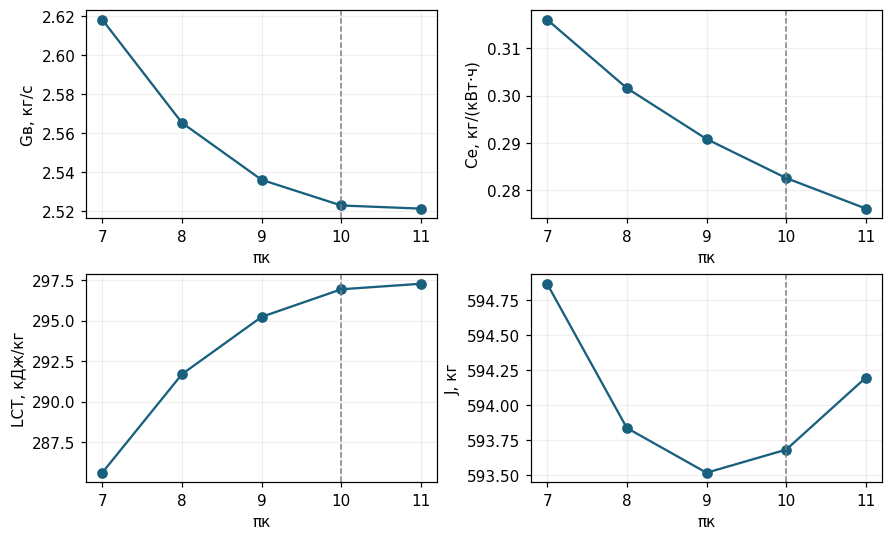

In [266]:
variants = pd.DataFrame()
variants['πк'] = pi_variants
variants['Gв, кг/с'] = air_flow_variants
variants['Gт, кг/с'] = fuel_flow_variants
variants['Gг, кг/с'] = gas_flow_variants
variants['Ce, кг/(кВт·ч)'] = fuel_specific_variants
variants['ηe'] = efficiency_variants
variants['LСТ, кДж/кг'] = work_st_variants / 1000
variants['Mосн, кг'] = core_mass_variants
variants['Mред, кг'] = Mgear
variants['Mдв, кг'] = engine_mass_variants
variants['Mт взл., кг'] = fuel_mass_variants
variants['J, кг'] = total_mass_variants
variants = variants.set_index("πк")
display(variants.round(4))
fig = plt.figure(figsize=(8, 4.8), constrained_layout=True)
axes = fig.subplots(2, 2)
for ax, key in zip(axes.flat, ["Gв, кг/с", "Ce, кг/(кВт·ч)", "LСТ, кДж/кг", "J, кг"]):
    ax.plot(variants.index, variants[key], "o-", color="#18607e")
    ax.axvline(pi_design, ls="--", color="gray", lw=1)
    ax.set(xlabel="πк", ylabel=key, xticks=variants.index)
    ax.grid(alpha=0.2)
plt.show()

<a id="properties"></a>
## Приложение Б. Полиномы теплоёмкости

Температура в К, результат в Дж/(кг·К), для газа $\alpha>0{,}2$. Введём $A=0{,}0025T-0{,}875$, $B=0{,}000025T^2-0{,}0275T+6{,}5625$, $C=0{,}001176T-0{,}88235$, $E=0{,}0000055556T^2-0{,}013056T+6{,}67$.

| Величина | Нижняя ветвь | Верхняя ветвь |
|---|---|---|
| $c_{pв}/4187$ | $0{,}2407+0{,}0193A+0{,}002B$ | $0{,}26+0{,}032C-0{,}00374E$ |
| $c_{pг}/4187$ | $0{,}2407+0{,}0174/\alpha+(0{,}0193+0{,}0093/\alpha)A+(0{,}002-0{,}001056/(\alpha-0{,}2))B$ | $0{,}26+0{,}0267/\alpha+(0{,}032+0{,}0133/\alpha)C-[0{,}00374+0{,}0094/(\alpha^2+10)]E$ |
| $c_{pm,в}/4187$ | $0{,}236+1{,}2\cdot10^{-5}(T-70)$ | $0{,}218+2{,}2\cdot10^{-5}(T+450)$ |
| $c_{pm,г}/4187$ | $0{,}236+(2{,}25/\alpha+1{,}2)10^{-5}(T-70)$ | $0{,}218+(1{,}25/\alpha+2{,}2)10^{-5}(T+450)$ |

Для истинных теплоёмкостей правая ветвь начинается с 750 К, для средних — с 700 К. Множитель 4187 соответствует пересчёту исходных коэффициентов теплоёмкости в Дж/(кг·К).

**Основа расчёта.** Исходный лист «С_учетом_охлаждения_многоступенч.xmcd» и перенесённый из него расчёт Jupyter. Для ступеней и профилирования в исходной работе использовано пособие В. Е. Михальцева и В. Д. Молякова «Теория и проектирование газовой турбины», с. 68–74 и 88–93. Для сверки исходного варианта до округления расхода использованы расчётная записка «Свободная турбина. Полный расчёт» и таблица скоростей и диаметров для выпуска 210,41 м/с.

<a id="symbols"></a>
## Словарь переменных

Звёздочке у давления или температуры соответствует буква `t` в именах `p0t_1`, `p2t_2`, `T5t_cycle`. Все давления хранятся в Па. Вывод в кПа выполняется делением на 1000. Одноимённые переменные предыдущих приближений помечены `_iter1`, `_iter2`.

### Цикл и режим

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `N_req` | $N_{зад}$ | Заданная мощность после редуктора | Вт |
| `pi_design` | $\pi_к^*$ | Проектная степень повышения полного давления компрессора | — |
| `n` | $n$ | Частота вращения свободной турбины | об/мин |
| `Ta` | $T_н$ | Температура наружного воздуха | К |
| `pa` | $p_н$ | Статическое давление атмосферы | Па |
| `R` | $R$ | Удельная газовая постоянная модели | Дж/(кг·К) |
| `sigma_in` | $\sigma_{вх}$ | Сохранение полного давления во входном устройстве | — |
| `eta_poly` | $\eta_{пол}$ | Политропический КПД компрессора | — |
| `sigma_burn` | $\sigma_{кс}$ | Сохранение полного давления в камере сгорания | — |
| `eta_burn` | $\eta_г$ | Коэффициент полноты сгорания | — |
| `Qfuel` | $Q_н$ | Низшая теплота сгорания топлива | Дж/кг |
| `l0` | $l_0$ | Стехиометрическая масса воздуха на 1 кг топлива | кг/кг |
| `leak` | $g_{ут}$ | Безвозвратные утечки в долях расхода воздуха компрессора | — |
| `cool` | $g_{охл}$ | Отбор на охлаждение в долях расхода воздуха компрессора | — |
| `T4t` | $T_4^*$ | Полная температура смеси в горле СА ТВД | К |
| `eta_hpt` | $\eta_{ТВД}$ | КПД ТВД по полным параметрам | — |
| `eta_mech` | $\eta_м$ | Механический КПД в балансе каждого вала | — |
| `eta_gear` | $\eta_р$ | КПД редуктора | — |

### Предварительная СТ и выпуск

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `eta_pre` | $\eta_{лоп,пред}$ | Лопаточный КПД в предварительном цикле | — |
| `c_pre` | $c_{пред}$ | Заданная скорость за СТ в предварительном расчёте | м/с |
| `rp` | $r_p$ | Отношение статических давлений атмосферы и газа за РК2 | — |
| `sigma_nozzle` | $\sigma_с$ | Отношение полных давлений на срезе и за РК2 | — |
| `height_ratio` | $\lambda$ | Отношение выходной высоты лопатки к среднему диаметру | — |
| `y0` | $y_0$ | Отношение скоростей для оценки числа ступеней | — |
| `mu` | $\mu$ | Коэффициент использования выходной скорости | — |
| `c_mean` | $\bar c_2$ | Принятая средняя выходная скорость за ступенью для оценки числа ступеней | м/с |

### Венцы и профили

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `reaction_I` | $\rho_I$ | Заданная реактивность I ступени на среднем радиусе | — |
| `reaction_II` | $\rho_{II}$ | Заданная реактивность II ступени на среднем радиусе | — |
| `angle1_I` | $\alpha_{1,I}$ | Угол абсолютной скорости за СА1 от направления вращения | ° |
| `angle1_II` | $\alpha_{1,II}$ | Угол абсолютной скорости за СА2 от направления вращения | ° |
| `angle2_I` | $\alpha_{2,I}$ | Угол абсолютной скорости за РК1 от направления против вращения | ° |
| `phi_I` | $\varphi_I$ | Коэффициент скорости соплового аппарата I ступени | — |
| `phi_II` | $\varphi_{II}$ | Коэффициент скорости соплового аппарата II ступени | — |
| `psi_I` | $\psi_I$ | Коэффициент скорости РК I ступени, подбор в исходной точке | — |
| `psi_II` | $\psi_{II}$ | Коэффициент скорости РК II ступени, подбор в исходной точке | — |
| `gap` | $\delta$ | Радиальный зазор обоих РК | м |
| `thickness` | $d_{max}/b$ | Относительная максимальная толщина профиля | — |
| `pitch_ratio` | $t_m/b$ | Заданный относительный шаг на среднем радиусе | — |

### Параметры дополнительных вариантов

| Имя в Python | В формулах | Физический смысл | Единица |
|---|---|---|---|
| `c_target` | $c_{ц}$ | Заданная скорость для обратного расчёта сопла | м/с |
| `stress_limit` | $[\sigma]$ | Принятое предельное напряжение в эмпирической оценке | МПа |
| `kn` | $k_n$ | Коэффициент эмпирической формулы напряжения | МПа/[м²·(об/мин)²] |
| `takeoff_min` | $\tau_{мин}$ | Продолжительность взлётного режима для оценки массы топлива | мин |
| `Kscheme` | $K_{сх}$ | Поправка на схему двигателя в формуле массы | — |
| `Kresource` | $K_{рес}$ | Поправка на ресурс двигателя в формуле массы | — |

### Цикл и размеры

| Имя в коде | Величина | Единица |
|---|---|---|
| `p_in` | Полное давление на входе в компрессор | Па |
| `p_comp_out` | Полное давление за компрессором | Па |
| `T_comp_out` | Полная температура за компрессором | К |
| `L_comp` | Удельная работа компрессора | Дж/кг воздуха |
| `fuel_ratio` | Топливо на 1 кг воздуха | кг/кг |
| `alpha_burn` | Избыток воздуха в КС | — |
| `alpha` | Избыток воздуха после смешения | — |
| `gas_mass_ratio` | Масса газа после смешения на 1 кг воздуха | кг/кг |
| `L_hpt` | Удельная работа ТВД | Дж/кг газа |
| `Tin` | Полная температура перед СТ | К |
| `pin` | Полное давление перед СТ | Па |
| `Hpt` | Располагаемый перепад СТ по циклу | Дж/кг |
| `Lpt` | Удельная работа СТ по циклу | Дж/кг |
| `Tpre` | Статическая температура за СТ по циклу | К |
| `T5t_cycle` | Полная температура за СТ по циклу | К |
| `p5t_cycle` | Полное давление за СТ по циклу | Па |
| `p5` | Статическое давление за СТ | Па |
| `G_pre` | Предварительный расход газа | кг/с |
| `G` | Проектный расход газа | кг/с |
| `Gair` | Расход воздуха компрессора | кг/с |
| `Gfuel` | Расход топлива | кг/с |
| `D` | Средний диаметр СТ | м |
| `u` | Окружная скорость на среднем диаметре | м/с |
| `z_est` | Оценочное число ступеней | — |

### Обозначения ступеней и выпуска

| Имя в коде | Величина | Единица |
|---|---|---|
| `T0t_1 / T0t_2` | Полная температура на входе в СА | К |
| `p0t_1 / p0t_2` | Полное давление на входе в СА | Па |
| `p1_1 / p1_2` | Статическое давление после СА | Па |
| `T1_1 / T1_2` | Статическая температура после СА | К |
| `H_1 / H_2` | Теплоперепад ступени | Дж/кг |
| `Hc_1 / Hc_2` | Перепад в СА | Дж/кг |
| `Hl_1 / Hl_2` | Перепад в РК | Дж/кг |
| `cp_1 / cp_2` | Теплоёмкость ступени | Дж/(кг·К) |
| `ca1_1 / ca1_2` | Осевая скорость за СА | м/с |
| `ca2_1 / ca2_2` | Осевая скорость за РК | м/с |
| `cu1_1 / cu1_2` | Окружная составляющая за СА | м/с |
| `cu2_1 / cu2_2` | Окружная составляющая за РК | м/с |
| `p2_1 / p2_2` | Статическое давление за колесом | Па |
| `T2_corr_1 / T2_corr_2` | Статическая температура после учёта потерь | К |
| `T2t_1 / T2t_2` | Полная температура за колесом | К |
| `p2t_1 / p2t_2` | Полное давление за колесом | Па |
| `pi_stage_1 / pi_stage_2` | Степень расширения до статического давления | — |
| `pi_stage_total_1 / pi_stage_total_2` | Степень расширения по полным давлениям | — |
| `L_1 / L_2` | Удельная работа после учёта потерь | Дж/кг |
| `Nshaft` | Мощность после редуктора | Вт |
| `delta_p5t` | Разность полного давления по ступеням и по циклу | Па |
| `p9t` | Полное давление на срезе выпуска | Па |
| `p9` | Статическое давление на срезе | Па |
| `c9` | Проектная скорость на срезе | м/с |
| `c9_ideal` | Скорость на срезе без потери полного давления | м/с |
| `c9_target` | Скорость для допустимого целевого варианта | м/с |

### Массивы по высоте и сводные таблицы

Один массив содержит значения одной величины. Например, `p_sa1` — статическое давление в 201 точке по высоте за первым СА, а `p_rk1` — за первым РК. Индексы 0, 100 и 200 соответствуют втулке, середине и периферии. В координатах профилей первый индекс — номер сечения из 12, второй — точка на профиле.

| Имя | Что можно посмотреть |
|---|---|
| `speeds` | Скорости и углы на трёх высотах |
| `thermal` | Статические параметры, местная реактивность и работа |
| `pressure_check` | Сравнение давлений за СТ |
| `stage_results` | Работа, параметры выхода и степени расширения |
| `detail_table` | Подробные параметры и потери ступеней |
| `geometry` | Геометрические параметры профилей |
| `profile_xyz` | Координаты x, y, r для CAD, мм |
| `variants` | Сравнение предварительных циклов при разных степенях сжатия |